# Single-Parent Family Affordability Gaps Across Virginia's 133 Localities

**Virginia Datathon 2026**

**Research question.** Where in Virginia are single-parent families most concentrated, and how does the
cost of housing in those localities compare with what those families can afford?

**Geography.** All 95 counties and 38 independent cities (133 localities, state FIPS `51`). Virginia's
independent cities are county-equivalents, so every locality appears exactly once at the Census
`county` summary level — no aggregation or crosswalking is required.

**Primary source.** U.S. Census Bureau, American Community Survey **2024 5-Year Estimates**
(period 2020–2024), table **`B11003` — Family Type by Presence and Age of Own Children Under 18 Years**,
retrieved from the Census Data API at `https://api.census.gov/data/2024/acs/acs5`.

**Why published estimates, not PUMS.** ACS public-use microdata is geocoded to Public Use Microdata
Areas, not localities, so locality-level single-parent counts cannot be recovered from it. The
published `B11003` tabulation is the authoritative locality-level source and carries official margins
of error.

### Definitional scope — read before interpreting any number

| Decision | What this notebook does |
|---|---|
| "Single parent" | Family households with a **male or female householder, no spouse present**, that have **own children of the householder under 18 years** (`B11003_010` + `B11003_016`). |
| Cohabiting partners | **Included** in the single-parent count. ACS "no spouse present" is about the absence of a *spouse*, not of a partner, so an unmarried cohabiting couple is counted here. This is a household-structure measure, not a legal-marital-status measure. |
| "Own children" | Biological, step, or adopted children of the householder. **Excludes** grandchildren, nieces/nephews, and foster children — so grandparent- and relative-headed caregiving families are not counted. |
| Universe | **Families**, not all households. The denominator `B11003_001` is total families, which excludes single-person and unrelated-roommate households. |
| Uncertainty | Every estimate is reported with its official 90% margin of error, and derived quantities propagate that error using the Census Bureau's published formulas. |

### Reproducibility

Requires a Census API key in a local `.env` file as `CENSUS_API_KEY` (data endpoints reject unkeyed
requests — they redirect to `missing_key.html`). Nothing is hard-coded or filled in by hand: every
value below is fetched live, and the cells fail loudly rather than substituting a fallback.

## 1 · Environment, API key, and variable verification

Before retrieving anything, this cell confirms the 2024 5-year vintage is published and verifies that
every `B11003` variable code still carries the label this analysis assumes. Census occasionally
re-letters table rows between vintages, so the codes are asserted against the live metadata rather
than trusted from documentation.

In [1]:
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

# ---- Source identifiers -----------------------------------------------------
YEAR = 2024
DATASET = "acs/acs5"
BASE = f"https://api.census.gov/data/{YEAR}/{DATASET}"
TABLE = "B11003"
VA_STATE_FIPS = "51"
EXPECTED_LOCALITIES = 133  # 95 counties + 38 independent cities

OUTDIR = Path("single_parent_affordability")
OUTDIR.mkdir(exist_ok=True)

# ---- API key ----------------------------------------------------------------
load_dotenv()  # reads CENSUS_API_KEY from .env; surrounding quotes are stripped
CENSUS_API_KEY = (os.environ.get("CENSUS_API_KEY") or "").strip()
assert CENSUS_API_KEY, "CENSUS_API_KEY not found in environment or .env"
print(f"Census API key loaded ({len(CENSUS_API_KEY)} characters).")

# ---- Confirm the vintage is published ---------------------------------------
dataset_meta = requests.get(f"{BASE}.json", timeout=60).json()["dataset"][0]
print(f"Dataset: {'/'.join(dataset_meta['c_dataset'])}  vintage={dataset_meta['c_vintage']}")

# ---- Verify every variable code in the table --------------------------------
table_meta = requests.get(f"{BASE}/groups/{TABLE}.json", timeout=60).json()["variables"]
labels = {
    code: var["label"].replace("Estimate!!", "").replace("!!", " > ")
    for code, var in table_meta.items()
    if code.startswith(f"{TABLE}_") and code.endswith("E")
}
print(f"\n{TABLE} — {len(labels)} estimate variables:")
for code in sorted(labels):
    print(f"  {code}  {labels[code]}")

# The three variables this analysis depends on, asserted by exact label text.
REQUIRED = {
    "B11003_001E": "Total:",
    "B11003_010E": (
        "Total: > Other family: > Male householder, no spouse present: "
        "> With own children of the householder under 18 years:"
    ),
    "B11003_016E": (
        "Total: > Other family: > Female householder, no spouse present: "
        "> With own children of the householder under 18 years:"
    ),
}
for code, expected_label in REQUIRED.items():
    assert labels[code] == expected_label, f"{code} label changed: {labels[code]!r}"
    assert f"{code[:-1]}M" in table_meta, f"No margin of error published for {code}"
print("\nAll required estimate and margin-of-error variables verified against live metadata.")

Census API key loaded (40 characters).


Dataset: acs/acs5  vintage=2024

B11003 — 20 estimate variables:
  B11003_001E  Total:
  B11003_002E  Total: > Married-couple family:
  B11003_003E  Total: > Married-couple family: > With own children of the householder under 18 years:
  B11003_004E  Total: > Married-couple family: > With own children of the householder under 18 years: > Under 6 years only
  B11003_005E  Total: > Married-couple family: > With own children of the householder under 18 years: > Under 6 years and 6 to 17 years
  B11003_006E  Total: > Married-couple family: > With own children of the householder under 18 years: > 6 to 17 years only
  B11003_007E  Total: > Married-couple family: > No own children of the householder under 18 years
  B11003_008E  Total: > Other family:
  B11003_009E  Total: > Other family: > Male householder, no spouse present:
  B11003_010E  Total: > Other family: > Male householder, no spouse present: > With own children of the householder under 18 years:
  B11003_011E  Total: > Other family

## 2 · Retrieve all 133 localities

One API call returns every Virginia county-equivalent. The Census API encodes non-response with
"jam values" (large negative sentinels such as `-666666666`); these are converted to `NaN` so they can
never be mistaken for real counts. The row count is asserted at 133 so a partial response fails rather
than passing silently.

In [2]:
# Estimate variables and their analysis-friendly names.
ESTIMATES = {
    "B11003_001E": "families_total",
    "B11003_010E": "sp_male_children",
    "B11003_016E": "sp_female_children",
}
MARGINS = {f"{code[:-1]}M": f"{name}_moe" for code, name in ESTIMATES.items()}

# Census API sentinels for suppressed / not-applicable values.
JAM_VALUES = {
    -111111111, -222222222, -333333333, -555555555,
    -666666666, -888888888, -999999999,
}

response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *ESTIMATES, *MARGINS]),
        "for": "county:*",
        "in": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=120,
)
response.raise_for_status()
assert "missing_key" not in response.url, "Census API rejected the key"

payload = response.json()
raw = pd.DataFrame(payload[1:], columns=payload[0])
assert len(raw) == EXPECTED_LOCALITIES, f"Expected {EXPECTED_LOCALITIES} localities, got {len(raw)}"

va = raw.rename(columns={**ESTIMATES, **MARGINS})
value_cols = [*ESTIMATES.values(), *MARGINS.values()]
va[value_cols] = va[value_cols].apply(pd.to_numeric, errors="coerce")

# Mask jam values so suppressed data reads as missing, not as a negative count.
jammed = int(va[value_cols].isin(JAM_VALUES).to_numpy().sum())
va[value_cols] = va[value_cols].mask(va[value_cols].isin(JAM_VALUES))

# Identifiers.
va["geoid"] = va["state"] + va["county"]
va["locality"] = va["NAME"].str.replace(", Virginia", "", regex=False)
va["locality_type"] = np.where(
    va["locality"].str.endswith(" County"), "County", "Independent city"
)
va = va[["geoid", "locality", "locality_type", *value_cols]].sort_values("locality").reset_index(drop=True)

print(f"Localities retrieved: {len(va)}")
print(va["locality_type"].value_counts().to_string())
print(f"Jam values masked to NaN: {jammed}")
print(f"Missing values remaining: {int(va[value_cols].isna().to_numpy().sum())}")
print(f"\nStatewide total families (sum of localities): {va['families_total'].sum():,.0f}")
display(va.head(10))

Localities retrieved: 133
locality_type
County              95
Independent city    38
Jam values masked to NaN: 0
Missing values remaining: 0

Statewide total families (sum of localities): 2,181,475


,geoid,locality,locality_type,families_total,sp_male_children,sp_female_children,families_total_moe,sp_male_children_moe,sp_female_children_moe
0,51001,Accomack County,County,9205,581,692,522,181,202
1,51003,Albemarle County,County,28396,896,2389,761,243,389
2,51510,Alexandria city,Independent city,34764,1176,2840,1076,356,362
3,51005,Alleghany County,County,3782,100,268,276,62,117
4,51007,Amelia County,County,4147,14,93,282,24,77
5,51009,Amherst County,County,8032,220,429,396,94,129
6,51011,Appomattox County,County,4504,181,472,268,105,155
7,51013,Arlington County,County,49498,1295,2740,1200,365,376
8,51015,Augusta County,County,20814,527,1268,733,181,255
9,51017,Bath County,County,1069,15,102,113,25,62


## 3 · Derive the single-parent measure with propagated margins of error

Single-parent families are the sum of the male- and female-householder rows. Margins of error are
combined with the Census Bureau's formula for a sum of estimates — the square root of the sum of
squared MOEs — and the share uses the Bureau's proportion formula, falling back to the ratio formula
when the radical goes negative. The coefficient of variation then flags which locality estimates are
too imprecise to rank.

In [3]:
Z90 = 1.645  # ACS margins of error are published at the 90% confidence level


def moe_sum(*moes):
    """MOE of a sum of independent estimates: sqrt(sum of squared MOEs)."""
    stacked = np.vstack([np.asarray(m, dtype=float) for m in moes])
    return np.sqrt(np.nansum(stacked ** 2, axis=0))


def moe_proportion(num, num_moe, den, den_moe):
    """
    MOE of a proportion where the numerator is a subset of the denominator
    (ACS General Handbook, 'Calculating Measures of Error for Derived Estimates').
    Falls back to the ratio formula when the radical is negative.
    """
    num, num_moe = np.asarray(num, float), np.asarray(num_moe, float)
    den, den_moe = np.asarray(den, float), np.asarray(den_moe, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = num / den
        radical = num_moe ** 2 - (p ** 2) * (den_moe ** 2)
        fallback = num_moe ** 2 + (p ** 2) * (den_moe ** 2)
        return np.sqrt(np.where(radical < 0, fallback, radical)) / den


# --- Single-parent families (count) ---
va["single_parent_families"] = va["sp_male_children"] + va["sp_female_children"]
va["single_parent_families_moe"] = moe_sum(va["sp_male_children_moe"], va["sp_female_children_moe"])

# --- Single-parent share of all families (percent) ---
share = moe_proportion(
    va["single_parent_families"], va["single_parent_families_moe"],
    va["families_total"], va["families_total_moe"],
)
va["single_parent_share_pct"] = va["single_parent_families"] / va["families_total"] * 100
va["single_parent_share_pct_moe"] = share * 100

# --- Reliability of each locality's count (coefficient of variation) ---
with np.errstate(divide="ignore", invalid="ignore"):
    va["count_cv_pct"] = (
        (va["single_parent_families_moe"] / Z90) / va["single_parent_families"] * 100
    )
va["reliability"] = pd.cut(
    va["count_cv_pct"],
    bins=[-np.inf, 15, 30, np.inf],
    labels=["High (CV<15%)", "Moderate (CV 15-30%)", "Low (CV>30%)"],
)

# --- Statewide benchmark, computed from the locality rows ---
state_sp = va["single_parent_families"].sum()
state_fam = va["families_total"].sum()
print(f"Virginia single-parent families (2020-2024): {state_sp:,.0f}")
print(f"Share of all Virginia families:              {state_sp / state_fam * 100:.2f}%")
print(f"Female-householder share of single parents:  "
      f"{va['sp_female_children'].sum() / state_sp * 100:.1f}%")
print("\nEstimate reliability across the 133 localities:")
print(va["reliability"].value_counts().reindex(
    ["High (CV<15%)", "Moderate (CV 15-30%)", "Low (CV>30%)"]).to_string())

report = [
    "locality", "locality_type", "single_parent_families", "single_parent_families_moe",
    "single_parent_share_pct", "single_parent_share_pct_moe", "count_cv_pct", "reliability",
]
print("\nHighest single-parent share of families:")
display(va.sort_values("single_parent_share_pct", ascending=False).head(10)[report]
          .round(2).reset_index(drop=True))
print("Lowest single-parent share of families:")
display(va.sort_values("single_parent_share_pct").head(10)[report]
          .round(2).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_families_{TABLE}_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows -> {out_path}")

Virginia single-parent families (2020-2024): 266,921
Share of all Virginia families:              12.24%
Female-householder share of single parents:  73.3%

Estimate reliability across the 133 localities:
reliability
High (CV<15%)           63
Moderate (CV 15-30%)    58
Low (CV>30%)            12

Highest single-parent share of families:


,locality,locality_type,single_parent_families,single_parent_families_moe,single_parent_share_pct,single_parent_share_pct_moe,count_cv_pct,reliability
0,Emporia city,Independent city,453,177.00,34.09,12.19,23.75,Moderate (CV 15-30%)
1,Covington city,Independent city,407,119.02,28.60,7.80,17.78,Moderate (CV 15-30%)
2,Petersburg city,Independent city,1771,346.88,27.25,4.96,11.91,High (CV<15%)
3,Danville city,Independent city,2434,315.78,24.71,2.93,7.89,High (CV<15%)
4,Portsmouth city,Independent city,5921,632.85,24.50,2.49,6.50,High (CV<15%)
5,Franklin city,Independent city,557,198.91,23.92,8.01,21.71,Moderate (CV 15-30%)
6,Buena Vista city,Independent city,409,127.80,23.88,6.96,19.00,Moderate (CV 15-30%)
7,Greensville County,County,513,119.20,23.64,5.12,14.13,High (CV<15%)
8,Martinsville city,Independent city,738,190.68,23.55,5.80,15.71,Moderate (CV 15-30%)
9,Waynesboro city,Independent city,1265,307.13,21.80,5.14,14.76,High (CV<15%)


Lowest single-parent share of families:


,locality,locality_type,single_parent_families,single_parent_families_moe,single_parent_share_pct,single_parent_share_pct_moe,count_cv_pct,reliability
0,Highland County,County,11,9.43,1.72,1.46,52.14,Low (CV>30%)
1,Craig County,County,32,40.45,2.52,3.17,76.84,Low (CV>30%)
2,Amelia County,County,107,80.65,2.58,1.94,45.82,Low (CV>30%)
3,Goochland County,County,269,132.10,3.51,1.71,29.85,Moderate (CV 15-30%)
4,Powhatan County,County,506,195.42,5.84,2.24,23.48,Moderate (CV 15-30%)
5,Giles County,County,256,88.12,5.92,2.01,20.92,Moderate (CV 15-30%)
6,Nelson County,County,228,101.95,5.96,2.63,27.18,Moderate (CV 15-30%)
7,Grayson County,County,246,90.51,5.98,2.17,22.37,Moderate (CV 15-30%)
8,Gloucester County,County,652,191.38,6.17,1.79,17.84,Moderate (CV 15-30%)
9,Patrick County,County,321,128.80,6.51,2.57,24.39,Moderate (CV 15-30%)


Saved 133 rows -> single_parent_affordability/va_single_parent_families_B11003_acs2024_5yr.csv


## 4 · Validation against the independently published state estimate

The 133 locality estimates should reconcile with Virginia's own published `B11003` row, which the
Census Bureau tabulates separately. This cell fetches the state-level estimate and asserts the
locality sums match it exactly, which confirms no locality was dropped, double-counted, or silently
coerced during retrieval.

In [4]:
state_response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *ESTIMATES]),
        "for": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=60,
)
state_response.raise_for_status()
state_payload = state_response.json()
state_row = dict(zip(state_payload[0], state_payload[1]))

checks = {
    "families_total": int(state_row["B11003_001E"]),
    "sp_male_children": int(state_row["B11003_010E"]),
    "sp_female_children": int(state_row["B11003_016E"]),
}
print(f"{'measure':<22}{'sum of 133':>14}{'state published':>18}{'difference':>13}")
for column, published in checks.items():
    locality_sum = int(va[column].sum())
    print(f"{column:<22}{locality_sum:>14,}{published:>18,}{locality_sum - published:>13,}")
    assert locality_sum == published, (
        f"{column}: localities sum to {locality_sum:,} but state publishes {published:,}"
    )

print("\nValidated: locality estimates reconcile exactly with the published state estimate.")

measure                   sum of 133   state published   difference
families_total             2,181,475         2,181,475            0
sp_male_children              71,254            71,254            0
sp_female_children           195,667           195,667            0

Validated: locality estimates reconcile exactly with the published state estimate.


## 5 · Narrowing the definition: separating cohabiting couples

`B11003` classifies a family by whether a **spouse** is present, not whether a **partner** is present.
A householder raising their own children alongside an unmarried partner is therefore counted as a
single parent above. For an affordability analysis that biases the result toward optimism, because a
cohabiting household can hold two earners and split rent and childcare.

Table **`B11012`** asks the sharper question — "no spouse **or partner** present" — and reports
cohabiting-couple households as their own category. Combining the two tables gives a defensible
**range** rather than a single contestable number:

- **Wide** (`B11003_010` + `B11003_016`): any householder with no spouse, with own children under 18.
- **Strict** (`B11012_010` + `B11012_015`): no spouse *or partner*, with children of the householder
  under 18 — genuinely one adult.
- **Cohabiting** (`B11012_006`): the wedge between them.

The two tables use slightly different wording ("own children of the householder" vs "children of the
householder"), so they are not required to agree exactly; this cell asserts they reconcile within 1%
statewide and reports the residual rather than hiding it.

In [5]:
# B11012 "Households by Type" - household-level, separates cohabiting couples.
STRICT = {
    "B11012_010E": "strict_sp_female",
    "B11012_015E": "strict_sp_male",
    "B11012_006E": "cohabiting_with_children",
}
STRICT_MARGINS = {f"{c[:-1]}M": f"{n}_moe" for c, n in STRICT.items()}

strict_response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *STRICT, *STRICT_MARGINS]),
        "for": "county:*",
        "in": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=120,
)
strict_response.raise_for_status()
strict_payload = strict_response.json()
strict_raw = pd.DataFrame(strict_payload[1:], columns=strict_payload[0])
assert len(strict_raw) == EXPECTED_LOCALITIES, f"Expected {EXPECTED_LOCALITIES}, got {len(strict_raw)}"

strict_df = strict_raw.rename(columns={**STRICT, **STRICT_MARGINS})
strict_cols = [*STRICT.values(), *STRICT_MARGINS.values()]
strict_df[strict_cols] = strict_df[strict_cols].apply(pd.to_numeric, errors="coerce")
strict_df[strict_cols] = strict_df[strict_cols].mask(strict_df[strict_cols].isin(JAM_VALUES))
strict_df["geoid"] = strict_df["state"] + strict_df["county"]

va = va.merge(strict_df[["geoid", *strict_cols]], on="geoid", how="left", validate="one_to_one")
assert va[strict_cols].notna().all().all(), "Missing B11012 values after merge"

# --- Strict single-parent households: no spouse OR partner, with children ---
va["single_parent_strict"] = va["strict_sp_female"] + va["strict_sp_male"]
va["single_parent_strict_moe"] = moe_sum(va["strict_sp_female_moe"], va["strict_sp_male_moe"])

# --- How much of the wide count is actually cohabiting couples ---
with np.errstate(divide="ignore", invalid="ignore"):
    va["cohabiting_pct_of_wide"] = (
        va["cohabiting_with_children"] / va["single_parent_families"] * 100
    )
    va["strict_cv_pct"] = (
        (va["single_parent_strict_moe"] / Z90) / va["single_parent_strict"] * 100
    )

# --- Validation 1: locality sums match the published state row ---
state_b11012 = requests.get(
    BASE,
    params={"get": ",".join(STRICT), "for": f"state:{VA_STATE_FIPS}", "key": CENSUS_API_KEY},
    timeout=60,
).json()
state_vals = dict(zip(state_b11012[0], state_b11012[1]))
for code, name in STRICT.items():
    locality_sum, published = int(va[name].sum()), int(state_vals[code])
    assert locality_sum == published, f"{name}: {locality_sum:,} vs state {published:,}"
print("Validated: B11012 locality estimates match the published state estimate exactly.")

# --- Validation 2: the two tables reconcile statewide ---
wide_total = int(va["single_parent_families"].sum())
strict_total = int(va["single_parent_strict"].sum())
cohab_total = int(va["cohabiting_with_children"].sum())
residual = strict_total + cohab_total - wide_total
residual_pct = abs(residual) / wide_total * 100
print(f"\nB11003 wide                 {wide_total:>10,}")
print(f"B11012 strict               {strict_total:>10,}")
print(f"B11012 cohabiting           {cohab_total:>10,}")
print(f"strict + cohabiting         {strict_total + cohab_total:>10,}")
print(f"residual vs wide            {residual:>10,}  ({residual_pct:.2f}%)")
assert residual_pct < 1.0, f"Tables disagree by {residual_pct:.2f}% - investigate before proceeding"

print(f"\nCohabiting couples are {cohab_total / wide_total * 100:.1f}% of the wide count statewide.")
print(f"Affordability-relevant range: {strict_total:,} to {wide_total:,} households")

# --- Where the definition matters most ---
span = [
    "locality", "locality_type", "single_parent_strict", "single_parent_families",
    "cohabiting_with_children", "cohabiting_pct_of_wide",
]
print("\nLocalities where cohabiting couples inflate the wide count most:")
display(va.loc[va["single_parent_families"] >= 500]
          .nlargest(10, "cohabiting_pct_of_wide")[span].round(1).reset_index(drop=True))
print("Localities least affected by the definition (wide ~ strict):")
display(va.loc[va["single_parent_families"] >= 500]
          .nsmallest(10, "cohabiting_pct_of_wide")[span].round(1).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_wide_vs_strict_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Validated: B11012 locality estimates match the published state estimate exactly.

B11003 wide                    266,921
B11012 strict                  200,974
B11012 cohabiting               66,174
strict + cohabiting            267,148
residual vs wide                   227  (0.09%)

Cohabiting couples are 24.8% of the wide count statewide.
Affordability-relevant range: 200,974 to 266,921 households

Localities where cohabiting couples inflate the wide count most:


,locality,locality_type,single_parent_strict,single_parent_families,cohabiting_with_children,cohabiting_pct_of_wide
0,Buchanan County,County,306,643,337,52.4
1,Greene County,County,432,815,383,47.0
2,Manassas city,Independent city,781,1472,691,46.9
3,Bristol city,Independent city,484,888,404,45.5
4,Rockbridge County,County,305,538,233,43.3
5,Orange County,County,657,1154,497,43.1
6,King William County,County,354,591,237,40.1
7,Wythe County,County,381,635,254,40.0
8,Powhatan County,County,305,506,201,39.7
9,Augusta County,County,1082,1795,713,39.7


Localities least affected by the definition (wide ~ strict):


,locality,locality_type,single_parent_strict,single_parent_families,cohabiting_with_children,cohabiting_pct_of_wide
0,Lynchburg city,Independent city,2779,3030,251,8.3
1,Colonial Heights city,Independent city,836,912,76,8.3
2,Westmoreland County,County,648,711,63,8.9
3,Danville city,Independent city,2140,2434,297,12.2
4,Halifax County,County,1141,1314,173,13.2
5,Hopewell city,Independent city,965,1120,155,13.8
6,Lee County,County,583,677,94,13.9
7,Cumberland County,County,490,574,84,14.6
8,Greensville County,County,433,513,80,15.6
9,Chesapeake city,Independent city,7845,9371,1526,16.3


Saved 133 rows x 25 columns -> single_parent_affordability/va_single_parent_wide_vs_strict_acs2024_5yr.csv


## 6 · Income and poverty: what these families actually have

Two sources are used here, for a specific reason.

**`B17010` (poverty status by family type) is the backbone.** It reports *counts*, which can be summed
across male- and female-householder families and across localities, and it is published for all 133
localities with no suppression. This is what makes a complete locality map possible.

**`B19126` (median family income by family type) is supporting evidence only.** Medians cannot be
averaged or added, so there is no valid way to combine the male and female rows into one
"single-parent median" — they are reported side by side and never merged. It is also suppressed where
samples are thin: the male row is missing in 29 localities and the female row in 11. Those gaps are
flagged, not filled.

**Three caveats that must travel with these numbers.**

1. `B17010` counts *related* children (includes nieces, nephews, grandchildren), while `B11003` counts
   *own* children. The `B17010` universe is therefore larger — 315,527 vs 266,921 statewide — so
   poverty **rates** from this table are sound but its counts must not be swapped into the earlier
   series.
2. Both tables use "no spouse present", which is the **wide** definition. No locality-level income or
   poverty table separates cohabiting couples, so the strict/wide range established in §5 cannot be
   carried into income. This is a real limitation and is reported as one.
3. Poverty thresholds are a federal minimum, not a measure of local affordability. A family above the
   poverty line in Arlington may still be unable to afford rent there. Housing cost comes next.

In [6]:
# B17010 - poverty status by family type (COUNTS: summable, complete coverage)
POVERTY = {
    "B17010_011E": "pov_below_male",
    "B17010_017E": "pov_below_female",
    "B17010_031E": "pov_above_male",
    "B17010_037E": "pov_above_female",
    "B17010_004E": "pov_below_married",
    "B17010_024E": "pov_above_married",
}
# B19126 - median family income (MEDIANS: never summed or averaged)
MEDIANS = {
    "B19126_003E": "median_income_married_kids",
    "B19126_007E": "median_income_single_father",
    "B19126_010E": "median_income_single_mother",
}
INCOME_MARGINS = {f"{c[:-1]}M": f"{n}_moe" for c, n in {**POVERTY, **MEDIANS}.items()}

income_response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *POVERTY, *MEDIANS, *INCOME_MARGINS]),
        "for": "county:*",
        "in": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=120,
)
income_response.raise_for_status()
income_payload = income_response.json()
income_raw = pd.DataFrame(income_payload[1:], columns=income_payload[0])
assert len(income_raw) == EXPECTED_LOCALITIES, f"Expected {EXPECTED_LOCALITIES}, got {len(income_raw)}"

income_df = income_raw.rename(columns={**POVERTY, **MEDIANS, **INCOME_MARGINS})
income_cols = [*POVERTY.values(), *MEDIANS.values(), *INCOME_MARGINS.values()]
income_df[income_cols] = income_df[income_cols].apply(pd.to_numeric, errors="coerce")
income_df[income_cols] = income_df[income_cols].mask(income_df[income_cols].isin(JAM_VALUES))
income_df["geoid"] = income_df["state"] + income_df["county"]

va = va.merge(income_df[["geoid", *income_cols]], on="geoid", how="left", validate="one_to_one")

# --- Validation: count variables must reconcile with the published state row ---
state_income = requests.get(
    BASE,
    params={"get": ",".join(POVERTY), "for": f"state:{VA_STATE_FIPS}", "key": CENSUS_API_KEY},
    timeout=60,
).json()
state_income_vals = dict(zip(state_income[0], state_income[1]))
for code, name in POVERTY.items():
    locality_sum, published = int(va[name].sum()), int(state_income_vals[code])
    assert locality_sum == published, f"{name}: {locality_sum:,} vs state {published:,}"
print("Validated: B17010 locality counts match the published state estimate exactly.")

# --- Single-parent family poverty rate (complete coverage, MOE propagated) ---
va["sp_poverty_below"] = va["pov_below_male"] + va["pov_below_female"]
va["sp_poverty_below_moe"] = moe_sum(va["pov_below_male_moe"], va["pov_below_female_moe"])
va["sp_poverty_universe"] = va["sp_poverty_below"] + va["pov_above_male"] + va["pov_above_female"]
va["sp_poverty_universe_moe"] = moe_sum(
    va["pov_below_male_moe"], va["pov_below_female_moe"],
    va["pov_above_male_moe"], va["pov_above_female_moe"],
)
va["sp_poverty_rate_pct"] = va["sp_poverty_below"] / va["sp_poverty_universe"] * 100
va["sp_poverty_rate_pct_moe"] = moe_proportion(
    va["sp_poverty_below"], va["sp_poverty_below_moe"],
    va["sp_poverty_universe"], va["sp_poverty_universe_moe"],
) * 100

# --- Married-couple comparison on an identical universe (families with children) ---
married_universe = va["pov_below_married"] + va["pov_above_married"]
va["married_poverty_rate_pct"] = va["pov_below_married"] / married_universe * 100
with np.errstate(divide="ignore", invalid="ignore"):
    # Undefined where no married-couple family with children is below poverty:
    # leave missing rather than reporting an infinite ratio.
    va["poverty_rate_ratio"] = np.where(
        va["married_poverty_rate_pct"] > 0,
        va["sp_poverty_rate_pct"] / va["married_poverty_rate_pct"],
        np.nan,
    )
    va["mother_income_pct_of_married"] = (
        va["median_income_single_mother"] / va["median_income_married_kids"] * 100
    )
undefined_ratio = int(va["poverty_rate_ratio"].isna().sum())
assert np.isfinite(va["poverty_rate_ratio"].dropna()).all(), "Infinite ratio survived the guard"
print(f"Poverty-rate ratio undefined in {undefined_ratio} localities "
      f"(no married-couple family with children below poverty).")

# --- Statewide summary ---
below, universe = va["sp_poverty_below"].sum(), va["sp_poverty_universe"].sum()
m_below, m_universe = va["pov_below_married"].sum(), married_universe.sum()
print(f"\nSingle-parent families with related children   {universe:>10,.0f}")
print(f"  ...with income below the poverty line        {below:>10,.0f}")
print(f"  poverty rate                                 {below / universe * 100:>9.1f}%")
print(f"Married-couple families, same universe         {m_universe:>10,.0f}")
print(f"  poverty rate                                 {m_below / m_universe * 100:>9.1f}%")
print(f"  => single-parent families are {(below / universe) / (m_below / m_universe):.1f}x "
      f"as likely to be in poverty")

print("\nMedian family income, statewide (reported separately - never averaged):")
for name in MEDIANS.values():
    covered = int(va[name].notna().sum())
    print(f"  {name:<30} {covered:>3}/133 localities published")

print("\nWhere single-parent poverty is highest (restricted to reliable estimates):")
pov_cols = ["locality", "locality_type", "single_parent_families", "sp_poverty_rate_pct",
            "sp_poverty_rate_pct_moe", "married_poverty_rate_pct", "poverty_rate_ratio"]
reliable = va.loc[va["reliability"] == "High (CV<15%)"]
display(reliable.nlargest(10, "sp_poverty_rate_pct")[pov_cols].round(1).reset_index(drop=True))
print("Where single-parent poverty is lowest (reliable estimates only):")
display(reliable.nsmallest(10, "sp_poverty_rate_pct")[pov_cols].round(1).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_income_poverty_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Validated: B17010 locality counts match the published state estimate exactly.
Poverty-rate ratio undefined in 8 localities (no married-couple family with children below poverty).

Single-parent families with related children      315,527
  ...with income below the poverty line            75,543
  poverty rate                                      23.9%
Married-couple families, same universe            688,132
  poverty rate                                       4.1%
  => single-parent families are 5.8x as likely to be in poverty

Median family income, statewide (reported separately - never averaged):
  median_income_married_kids     132/133 localities published
  median_income_single_father    104/133 localities published
  median_income_single_mother    122/133 localities published

Where single-parent poverty is highest (restricted to reliable estimates):


,locality,locality_type,single_parent_families,sp_poverty_rate_pct,sp_poverty_rate_pct_moe,married_poverty_rate_pct,poverty_rate_ratio
0,Tazewell County,County,1262,47.5,10.6,11.3,4.2
1,Danville city,Independent city,2434,41.9,7.6,10.1,4.1
2,Lynchburg city,Independent city,3030,40.7,9.6,6.0,6.8
3,Henry County,County,1592,39.8,10.2,7.7,5.2
4,Carroll County,County,838,39.5,11.9,9.5,4.1
5,Petersburg city,Independent city,1771,36.9,8.2,8.5,4.3
6,Mecklenburg County,County,1292,36.7,10.3,4.5,8.2
7,Harrisonburg city,Independent city,1557,36.2,9.5,7.9,4.6
8,Shenandoah County,County,1368,35.1,8.1,6.7,5.3
9,Norfolk city,Independent city,11156,34.7,3.0,6.5,5.4


Where single-parent poverty is lowest (reliable estimates only):


,locality,locality_type,single_parent_families,sp_poverty_rate_pct,sp_poverty_rate_pct_moe,married_poverty_rate_pct,poverty_rate_ratio
0,Greensville County,County,513,4.3,5.1,4.4,1.0
1,York County,County,1949,11.3,5.2,2.3,4.8
2,Loudoun County,County,9294,11.6,3.1,2.0,5.8
3,Roanoke County,County,3431,11.7,4.2,3.3,3.5
4,Stafford County,County,4014,12.5,3.7,3.3,3.8
5,Fauquier County,County,1709,13.6,6.7,6.3,2.2
6,Staunton city,Independent city,1050,13.9,6.1,14.5,1.0
7,Hanover County,County,2776,14.6,5.3,3.3,4.4
8,Prince William County,County,13330,14.9,2.7,3.8,3.9
9,Waynesboro city,Independent city,1265,15.9,9.7,5.5,2.9


Saved 133 rows x 52 columns -> single_parent_affordability/va_single_parent_income_poverty_acs2024_5yr.csv


## 7 · Segmenting the cohort: sex, age of children, race and ethnicity

Treating single-parent families as one block hides the disparities that matter. Four segmentation
axes were assessed against what is actually published for all 133 localities:

| Axis | Locality-level feasibility |
|---|---|
| **Householder sex** | **Full.** Already carried in the `B17010` columns retrieved in §6. |
| **Age of own children** | **Full.** `B11003` splits each householder sex into under-6-only, under-6-and-6-to-17, and 6-to-17-only, published for all 133 with no suppression. |
| **Race and ethnicity** | **Statewide only.** The `B17010A`-`B17010I` iterations are published, but Virginia's small localities yield *structural zeros* rather than suppression — single Hispanic fathers below poverty is zero in 101 of 133 localities. Statewide rates are sound; locality rates would be noise, so none are computed. |
| **Never-married vs divorced/separated** | **Not possible.** No published ACS table crosses householder marital status with single-parent family status; the only marital-status-by-children table, `B10057`, covers grandparents. This segmentation exists solely in PUMS, which is PUMA-coded and cannot be mapped to localities. It is therefore out of scope for this notebook rather than approximated. |

Two notes on the race iterations. `B17010H` (White alone, not Hispanic or Latino) is used rather than
`B17010A` (White alone), because `B17010A` includes Hispanic White householders who also appear in
`B17010I`. And these are the race and ethnicity of the **householder**, not of the children.

In [7]:
# ---- 1. Poverty rate by householder sex (no new request: B17010 columns are already merged) ----
for sex, below, above in [("father", "pov_below_male", "pov_above_male"),
                          ("mother", "pov_below_female", "pov_above_female")]:
    universe = va[below] + va[above]
    va[f"{sex}_poverty_universe"] = universe
    va[f"{sex}_poverty_rate_pct"] = va[below] / universe * 100
    va[f"{sex}_poverty_rate_pct_moe"] = moe_proportion(
        va[below], va[f"{below}_moe"], universe,
        moe_sum(va[f"{below}_moe"], va[f"{above}_moe"]),
    ) * 100

# ---- 2. Age of own children (B11003 age detail) ----
CHILD_AGE = {
    "B11003_011E": "father_under6_only",
    "B11003_012E": "father_under6_and_6to17",
    "B11003_013E": "father_6to17_only",
    "B11003_017E": "mother_under6_only",
    "B11003_018E": "mother_under6_and_6to17",
    "B11003_019E": "mother_6to17_only",
}
CHILD_AGE_MARGINS = {f"{c[:-1]}M": f"{n}_moe" for c, n in CHILD_AGE.items()}

age_response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *CHILD_AGE, *CHILD_AGE_MARGINS]),
        "for": "county:*",
        "in": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=120,
)
age_response.raise_for_status()
age_payload = age_response.json()
age_raw = pd.DataFrame(age_payload[1:], columns=age_payload[0])
assert len(age_raw) == EXPECTED_LOCALITIES, f"Expected {EXPECTED_LOCALITIES}, got {len(age_raw)}"

age_df = age_raw.rename(columns={**CHILD_AGE, **CHILD_AGE_MARGINS})
age_cols = [*CHILD_AGE.values(), *CHILD_AGE_MARGINS.values()]
age_df[age_cols] = age_df[age_cols].apply(pd.to_numeric, errors="coerce")
age_df[age_cols] = age_df[age_cols].mask(age_df[age_cols].isin(JAM_VALUES))
age_df["geoid"] = age_df["state"] + age_df["county"]
va = va.merge(age_df[["geoid", *age_cols]], on="geoid", how="left", validate="one_to_one")

# Families with any child under 6 - the childcare-exposed group.
under6_parts = ["father_under6_only", "father_under6_and_6to17",
                "mother_under6_only", "mother_under6_and_6to17"]
va["sp_with_child_under6"] = va[under6_parts].sum(axis=1)
va["sp_with_child_under6_moe"] = moe_sum(*[va[f"{c}_moe"] for c in under6_parts])
va["sp_school_age_only"] = va["father_6to17_only"] + va["mother_6to17_only"]
va["pct_with_child_under6"] = va["sp_with_child_under6"] / va["single_parent_families"] * 100
va["pct_with_child_under6_moe"] = moe_proportion(
    va["sp_with_child_under6"], va["sp_with_child_under6_moe"],
    va["single_parent_families"], va["single_parent_families_moe"],
) * 100

# Age detail must reconstruct the §2 total exactly (same table, finer rows).
rebuilt = va["sp_with_child_under6"] + va["sp_school_age_only"]
assert (rebuilt == va["single_parent_families"]).all(), "Age detail does not sum to the §2 total"
print("Validated: age detail reconstructs the single-parent total in all 133 localities.")

# ---- 3. Race and ethnicity of householder: STATEWIDE ONLY ----
RACE_ITERATIONS = {
    "B17010H": "White alone, not Hispanic",
    "B17010B": "Black alone",
    "B17010I": "Hispanic or Latino",
    "B17010D": "Asian alone",
    "B17010C": "Am. Indian / Alaska Native",
    "B17010G": "Two or more races",
    "B17010": "All single-parent families",
}
race_rows = []
for table, label in RACE_ITERATIONS.items():
    cols = [f"{table}_{i:03d}E" for i in (11, 17, 31, 37)]
    moes = [f"{c[:-1]}M" for c in cols]
    resp = requests.get(
        BASE,
        params={"get": ",".join(cols + moes), "for": f"state:{VA_STATE_FIPS}",
                "key": CENSUS_API_KEY},
        timeout=60,
    )
    resp.raise_for_status()
    row = dict(zip(resp.json()[0], resp.json()[1]))
    vals = {k: (np.nan if row[k] is None or int(row[k]) in JAM_VALUES else int(row[k]))
            for k in cols + moes}
    below = vals[cols[0]] + vals[cols[1]]
    below_moe = moe_sum([vals[moes[0]]], [vals[moes[1]]])[0]
    universe = below + vals[cols[2]] + vals[cols[3]]
    universe_moe = moe_sum(*[[vals[m]] for m in moes])[0]
    rate_moe = moe_proportion([below], [below_moe], [universe], [universe_moe])[0] * 100
    race_rows.append({
        "group": label, "table": table, "families": universe,
        "below_poverty": below, "poverty_rate_pct": below / universe * 100,
        "poverty_rate_pct_moe": rate_moe,
    })
race = pd.DataFrame(race_rows).sort_values("poverty_rate_pct", ascending=False)

# ---- Reporting ----
f_below, f_univ = va["pov_below_male"].sum(), va["father_poverty_universe"].sum()
m_below, m_univ = va["pov_below_female"].sum(), va["mother_poverty_universe"].sum()
print(f"\nPoverty rate by householder sex, statewide:")
print(f"  single fathers  {f_below:>8,.0f} / {f_univ:>8,.0f}  = {f_below / f_univ * 100:>5.1f}%")
print(f"  single mothers  {m_below:>8,.0f} / {m_univ:>8,.0f}  = {m_below / m_univ * 100:>5.1f}%")
print(f"  mothers are {(m_below / m_univ) / (f_below / f_univ):.1f}x as likely to be in poverty")

u6, sa = va["sp_with_child_under6"].sum(), va["sp_school_age_only"].sum()
print(f"\nAge of own children, statewide:")
print(f"  has a child under 6     {u6:>8,.0f}  ({u6 / (u6 + sa) * 100:.1f}%)  <- childcare-exposed")
print(f"  school age only (6-17)  {sa:>8,.0f}  ({sa / (u6 + sa) * 100:.1f}%)")

print("\nPoverty rate by race/ethnicity of householder (STATEWIDE ONLY - see note above):")
display(race.round(1).reset_index(drop=True))

seg = ["locality", "single_parent_families", "mother_poverty_rate_pct", "father_poverty_rate_pct",
       "pct_with_child_under6", "pct_with_child_under6_moe"]
reliable = va.loc[va["reliability"] == "High (CV<15%)"]
print("Highest share of single-parent families with a child under 6 (reliable estimates):")
display(reliable.nlargest(10, "pct_with_child_under6")[seg].round(1).reset_index(drop=True))

race.to_csv(OUTDIR / f"va_single_parent_poverty_by_race_statewide_acs{YEAR}_5yr.csv", index=False)
out_path = OUTDIR / f"va_single_parent_segmented_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Validated: age detail reconstructs the single-parent total in all 133 localities.



Poverty rate by householder sex, statewide:
  single fathers    10,691 /   82,460  =  13.0%
  single mothers    64,852 /  233,067  =  27.8%
  mothers are 2.1x as likely to be in poverty

Age of own children, statewide:
  has a child under 6       92,620  (34.7%)  <- childcare-exposed
  school age only (6-17)   174,301  (65.3%)

Poverty rate by race/ethnicity of householder (STATEWIDE ONLY - see note above):


,group,table,families,below_poverty,poverty_rate_pct,poverty_rate_pct_moe
0,Black alone,B17010B,112163,31528,28.1,1.4
1,Hispanic or Latino,B17010I,46469,12853,27.7,2.0
2,Two or more races,B17010G,31527,8180,25.9,2.5
3,Am. Indian / Alaska Native,B17010C,1724,426,24.7,8.5
4,All single-parent families,B17010,315527,75543,23.9,0.7
5,"White alone, not Hispanic",B17010H,133975,26878,20.1,1.0
6,Asian alone,B17010D,9029,1171,13.0,2.3


Highest share of single-parent families with a child under 6 (reliable estimates):


,locality,single_parent_families,mother_poverty_rate_pct,father_poverty_rate_pct,pct_with_child_under6,pct_with_child_under6_moe
0,Shenandoah County,1368,38.0,25.9,58.8,14.1
1,Carroll County,838,43.3,32.3,52.9,16.9
2,Petersburg city,1771,40.5,0.0,51.2,12.4
3,Waynesboro city,1265,22.7,5.9,48.7,13.6
4,Campbell County,1630,26.6,28.4,47.2,10.8
5,Norfolk city,11156,38.6,18.5,44.4,4.5
6,Alexandria city,4016,20.3,7.2,43.6,8.6
7,Danville city,2434,45.0,24.6,43.5,11.2
8,Spotsylvania County,3979,21.9,7.9,43.5,8.7
9,Prince George County,1557,26.2,8.6,42.9,13.0


Saved 133 rows x 75 columns -> single_parent_affordability/va_single_parent_segmented_acs2024_5yr.csv


## 8 · Housing cost and the affordability gap

This is the step that turns a poverty count into an affordability measure. Poverty thresholds are
federal and identical in Arlington and Lee County; rent is not.

**Cost side.** `B25031_004` gives the median gross rent for a **2-bedroom** unit — the realistic
requirement for a parent with children, rather than the all-unit median which is pulled down by
studios. It is published for 131 of 133 localities; the two gaps are reported, never backfilled.
`B25064` (all-unit median rent) is retrieved alongside it for completeness, but is **not** substituted
for the 2-bedroom figure.

**Exposure side.** `B25115` splits single-parent families into owners and renters. This matters:
rent burden only applies to the 58.7% who rent, and it reconciles exactly to the 266,921 wide count
from §2, confirming both tables use the same universe.

**Income side.** Two measures. The single-mother median from §6 (`B19126_010`, 122 localities) is the
headline, since mothers head 73% of these families. `B19128` (aggregate income) additionally allows a
**valid combined mean** across both householder sexes — aggregates can be summed where medians cannot
— available for about 120 localities.

**The affordability test.** A household is cost-burdened above **30% of gross income on housing**, the
standard HUD definition. So the affordable monthly rent is `income / 12 × 0.30`, and the gap is the
median 2-bedroom rent minus that figure. A positive gap means a single mother earning her locality's
median income **cannot afford the median 2-bedroom unit in her own locality**.

In [8]:
HOUSING = {
    "B25031_004E": "median_rent_2br",
    "B25064_001E": "median_rent_all_units",
    "B25071_001E": "median_rent_pct_income_all_renters",
    "B25115_022E": "sp_renter_father",
    "B25115_025E": "sp_renter_mother",
    "B25115_009E": "sp_owner_father",
    "B25115_012E": "sp_owner_mother",
    "B19128_007E": "aggregate_income_father",
    "B19128_010E": "aggregate_income_mother",
}
HOUSING_MARGINS = {f"{c[:-1]}M": f"{n}_moe" for c, n in HOUSING.items()}

housing_response = requests.get(
    BASE,
    params={
        "get": ",".join(["NAME", *HOUSING, *HOUSING_MARGINS]),
        "for": "county:*",
        "in": f"state:{VA_STATE_FIPS}",
        "key": CENSUS_API_KEY,
    },
    timeout=120,
)
housing_response.raise_for_status()
housing_payload = housing_response.json()
housing_raw = pd.DataFrame(housing_payload[1:], columns=housing_payload[0])
assert len(housing_raw) == EXPECTED_LOCALITIES, f"Expected {EXPECTED_LOCALITIES}, got {len(housing_raw)}"

housing_df = housing_raw.rename(columns={**HOUSING, **HOUSING_MARGINS})
housing_cols = [*HOUSING.values(), *HOUSING_MARGINS.values()]
housing_df[housing_cols] = housing_df[housing_cols].apply(pd.to_numeric, errors="coerce")
housing_df[housing_cols] = housing_df[housing_cols].mask(housing_df[housing_cols].isin(JAM_VALUES))
housing_df["geoid"] = housing_df["state"] + housing_df["county"]
va = va.merge(housing_df[["geoid", *housing_cols]], on="geoid", how="left", validate="one_to_one")

for name in ["median_rent_2br", "aggregate_income_father", "aggregate_income_mother"]:
    print(f"  {name}: {int(va[name].notna().sum())}/133 localities published")

# --- Tenure: who is actually exposed to rent ---
va["sp_renters"] = va["sp_renter_father"] + va["sp_renter_mother"]
va["sp_owners"] = va["sp_owner_father"] + va["sp_owner_mother"]
va["sp_renters_moe"] = moe_sum(va["sp_renter_father_moe"], va["sp_renter_mother_moe"])
va["sp_renter_share_pct"] = va["sp_renters"] / (va["sp_renters"] + va["sp_owners"]) * 100

# B25115 must describe the same universe as B11003: a hard cross-table check.
assert (va["sp_renters"] + va["sp_owners"] == va["single_parent_families"]).all(), \
    "B25115 tenure split does not reconcile with the B11003 single-parent total"
print("Validated: tenure split reconciles exactly with the §2 single-parent total in all 133 localities.")

# --- Combined mean income (aggregates ARE summable; medians are not) ---
with np.errstate(divide="ignore", invalid="ignore"):
    va["mean_income_single_parent"] = (
        (va["aggregate_income_father"] + va["aggregate_income_mother"])
        / va["single_parent_families"]
    )

# --- The affordability test: 30% of gross income (HUD cost-burden standard) ---
AFFORDABLE_SHARE = 0.30
va["affordable_rent_mother"] = va["median_income_single_mother"] / 12 * AFFORDABLE_SHARE
va["rent_gap_2br_monthly"] = va["median_rent_2br"] - va["affordable_rent_mother"]
# MOE of the difference: the income term is scaled by 0.30/12 before combining.
va["rent_gap_2br_monthly_moe"] = np.sqrt(
    va["median_rent_2br_moe"] ** 2
    + (AFFORDABLE_SHARE / 12 * va["median_income_single_mother_moe"]) ** 2
)
with np.errstate(divide="ignore", invalid="ignore"):
    va["rent_burden_2br_pct"] = (
        va["median_rent_2br"] * 12 / va["median_income_single_mother"] * 100
    )
va["rent_2br_unaffordable"] = np.where(
    va["rent_gap_2br_monthly"].isna(), np.nan, va["rent_gap_2br_monthly"] > 0
)

# --- Validation: tenure counts match the published state row ---
state_housing = requests.get(
    BASE,
    params={"get": "B25115_022E,B25115_025E,B25115_009E,B25115_012E",
            "for": f"state:{VA_STATE_FIPS}", "key": CENSUS_API_KEY},
    timeout=60,
).json()
state_h = dict(zip(state_housing[0], state_housing[1]))
for code, name in [("B25115_022E", "sp_renter_father"), ("B25115_025E", "sp_renter_mother"),
                   ("B25115_009E", "sp_owner_father"), ("B25115_012E", "sp_owner_mother")]:
    assert int(va[name].sum()) == int(state_h[code]), f"{name} does not match state"
print("Validated: B25115 locality counts match the published state estimate exactly.")

# --- Reporting ---
renters, owners = va["sp_renters"].sum(), va["sp_owners"].sum()
print(f"\nSingle-parent families by tenure, statewide:")
print(f"  renters {renters:>9,.0f}  ({renters / (renters + owners) * 100:.1f}%)  <- exposed to rent")
print(f"  owners  {owners:>9,.0f}  ({owners / (renters + owners) * 100:.1f}%)")

tested = va.dropna(subset=["rent_gap_2br_monthly"])
short = tested.loc[tested["rent_gap_2br_monthly"] > 0]
print(f"\nAffordability test (median 2-bedroom rent vs 30% of median single-mother income):")
print(f"  localities with both figures published   {len(tested):>3} of 133")
print(f"  where the median 2BR is UNAFFORDABLE     {len(short):>3} ({len(short) / len(tested) * 100:.0f}%)")
print(f"  median monthly shortfall in those        ${short['rent_gap_2br_monthly'].median():>8,.0f}")
print(f"  median rent burden statewide             "
      f"{tested['rent_burden_2br_pct'].median():>8.1f}% of income")

gap_cols = ["locality", "locality_type", "single_parent_families", "sp_renter_share_pct",
            "median_income_single_mother", "median_rent_2br", "affordable_rent_mother",
            "rent_gap_2br_monthly", "rent_burden_2br_pct"]
print("\nLargest monthly affordability gap for a median-income single mother:")
display(tested.nlargest(12, "rent_gap_2br_monthly")[gap_cols].round(0).reset_index(drop=True))
print("Localities where the median 2-bedroom remains affordable:")
display(tested.nsmallest(8, "rent_gap_2br_monthly")[gap_cols].round(0).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_affordability_gap_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

  median_rent_2br: 131/133 localities published
  aggregate_income_father: 119/133 localities published
  aggregate_income_mother: 120/133 localities published
Validated: tenure split reconciles exactly with the §2 single-parent total in all 133 localities.


Validated: B25115 locality counts match the published state estimate exactly.

Single-parent families by tenure, statewide:
  renters   156,566  (58.7%)  <- exposed to rent
  owners    110,355  (41.3%)

Affordability test (median 2-bedroom rent vs 30% of median single-mother income):
  localities with both figures published   120 of 133
  where the median 2BR is UNAFFORDABLE      66 (55%)
  median monthly shortfall in those        $     288
  median rent burden statewide                 32.1% of income

Largest monthly affordability gap for a median-income single mother:


,locality,locality_type,single_parent_families,sp_renter_share_pct,median_income_single_mother,median_rent_2br,affordable_rent_mother,rent_gap_2br_monthly,rent_burden_2br_pct
0,Alexandria city,Independent city,4016,83.0,55945.0,2362.0,1399.0,963.0,51.0
1,Fairfax city,Independent city,424,62.0,48250.0,2142.0,1206.0,936.0,53.0
2,Albemarle County,County,3285,54.0,37411.0,1686.0,935.0,751.0,54.0
3,Williamsburg city,Independent city,318,84.0,31385.0,1391.0,785.0,606.0,53.0
4,Charlottesville city,Independent city,1467,62.0,39526.0,1593.0,988.0,605.0,48.0
5,Arlington County,County,4035,60.0,82713.0,2666.0,2068.0,598.0,39.0
6,Lexington city,Independent city,129,92.0,19491.0,1073.0,487.0,586.0,66.0
7,Richmond city,Independent city,9409,76.0,36067.0,1445.0,902.0,543.0,48.0
8,Winchester city,Independent city,1217,77.0,39543.0,1496.0,989.0,507.0,45.0
9,Fairfax County,County,23500,59.0,70841.0,2273.0,1771.0,502.0,39.0


Localities where the median 2-bedroom remains affordable:


,locality,locality_type,single_parent_families,sp_renter_share_pct,median_income_single_mother,median_rent_2br,affordable_rent_mother,rent_gap_2br_monthly,rent_burden_2br_pct
0,Fluvanna County,County,506,14.0,103205.0,1183.0,2580.0,-1397.0,14.0
1,Grayson County,County,246,46.0,59091.0,779.0,1477.0,-698.0,16.0
2,Clarke County,County,278,29.0,80145.0,1316.0,2004.0,-688.0,20.0
3,Charles City County,County,146,40.0,61705.0,917.0,1543.0,-626.0,18.0
4,Powhatan County,County,506,26.0,56219.0,866.0,1405.0,-539.0,18.0
5,Nelson County,County,228,43.0,57745.0,953.0,1444.0,-491.0,20.0
6,Botetourt County,County,729,26.0,56607.0,980.0,1415.0,-435.0,21.0
7,New Kent County,County,563,19.0,62995.0,1158.0,1575.0,-417.0,22.0


Saved 133 rows x 103 columns -> single_parent_affordability/va_single_parent_affordability_gap_acs2024_5yr.csv


## 9 · Childcare, transportation and a budget benchmark (Virginia Datathon 2026 datasets)

The 174 datasets released for the Datathon were reviewed for anything that adds a cost the Census does
not publish. Three are used here; the rest were either irrelevant to this question or too sparse for
133 localities.

| Dataset | Use | Coverage |
|---|---|---|
| **National Database of Childcare Prices** (US DOL Women's Bureau) | Annual childcare price by **age of child** and **care setting** | **All 133 localities** |
| **Housing + Transportation Affordability Index** (CNT) | Annual transportation cost, auto ownership, VMT, transit share | **All 133 localities** |
| **ALICE Household Survival Budget 2024** (United For ALICE) | Benchmark: the minimum a single adult with one child needs | Statewide only |

**Rejected:** *True Cost of Economic Security* covers only 9 of 133 Virginia localities. *Monthly
Eviction Filings* is ZIP-code or statewide, not locality. The energy, Medicare and drug-pricing
datasets — roughly half the 174 — do not bear on this question.

**Four caveats that must travel with this section.**

1. **Mixed vintages.** ACS is 2020-2024, childcare prices are 2022 collected and inflation-adjusted to
   2024, the H+T Index is 2022, and the ALICE budget is 2024. These are *not* a single consistent year
   and the combined budget is therefore a planning estimate, not a measured quantity.
2. **No margins of error.** Neither the childcare nor the H+T data publishes uncertainty, so derived
   budget figures here cannot carry the error bars that §§3-8 do. They are reported without false
   precision.
3. **One child, not the real family.** Childcare price is per child. 34.7% of these families have a
   child under 6, and many have more than one child, so this understates the true cost.
4. **The transportation figure is not single-parent specific.** The H+T Index models a regional typical
   household at area median income, so it describes the locality's cost structure rather than this
   cohort's actual spending.

The budget assembled below is deliberately **partial** — rent, childcare and transportation only. Food
and health care are not included, which is precisely why the ALICE budget is used alongside it as the
complete benchmark.

In [9]:
DATA_VA = "https://data.virginia.gov/dataset"
NDCP_URL = (f"{DATA_VA}/1a2863ff-08f2-46e3-a050-e855eea5f8f2/resource/"
            "9477c05c-5ce1-4ea8-baf9-522cd6e89c8a/download/ndcp-price.csv")
HT_URL = (f"{DATA_VA}/f5384e44-b405-4805-9ac8-338853f5cfab/resource/"
          "72f68781-f7a8-4961-a647-017aadf3bb4c/download/htaindex2022_data_counties_51.csv")
ALICE_URL = (f"{DATA_VA}/a0efb5e1-b659-4528-8239-d324a451922f/resource/"
             "3b32dc19-9acd-466b-9a7e-6ebe13f5670e/download/household-survival-budget-virginia-2024.xlsx")

# ---- 1. Childcare prices (file is transposed: rows are age/setting, columns are localities) ----
def fetch(url):
    """data.virginia.gov rejects pandas' default urllib agent, so fetch via requests."""
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    return response.content

ndcp = pd.read_csv(io.StringIO(fetch(NDCP_URL).decode("utf-16")), sep="\t", header=1)
ndcp.columns = [str(c).strip() for c in ndcp.columns]
AGE, SETTING, METRIC = ndcp.columns[0], ndcp.columns[1], ndcp.columns[2]
ndcp_localities = [c for c in ndcp.columns[3:] if c and not c.startswith("Unnamed")]
assert len(ndcp_localities) == EXPECTED_LOCALITIES, f"NDCP has {len(ndcp_localities)} localities"

def ndcp_price(age, setting, metric="Price2024"):
    """One row of the transposed NDCP file as a numeric series indexed by locality name."""
    row = ndcp[(ndcp[AGE] == age) & (ndcp[SETTING] == setting) & (ndcp[METRIC] == metric)]
    assert len(row) == 1, f"Expected 1 row for {age}/{setting}/{metric}, got {len(row)}"
    values = row[ndcp_localities].iloc[0].astype(str).str.replace(r"[($),]", "", regex=True)
    return pd.to_numeric(values, errors="coerce")

# Our locality names -> NDCP names ("Accomack County" -> "Accomack", "Fairfax city" -> "Fairfax City").
def to_ndcp_name(locality):
    if locality.endswith(" County"):
        return locality[: -len(" County")]
    if locality.endswith(" city"):
        return locality[: -len(" city")] + " City"
    return locality

va["ndcp_name"] = va["locality"].map(to_ndcp_name)
assert set(va["ndcp_name"]) == set(ndcp_localities), "NDCP locality names do not match 1:1"
print("Validated: all 133 localities matched to NDCP by name "
      "(county/city collisions such as Fairfax and Richmond resolved).")

for age, column in [("Toddler", "childcare_toddler_annual"),
                    ("School-age", "childcare_school_age_annual"),
                    ("Infant", "childcare_infant_annual")]:
    va[column] = va["ndcp_name"].map(ndcp_price(age, "Center-based"))
    assert va[column].notna().all(), f"Missing {column}"

# ---- 2. Transportation cost (H+T Index) ----
ht = pd.read_csv(io.BytesIO(fetch(HT_URL)))
ht["geoid"] = ht["county"].astype(str).str.replace('"', "", regex=False).str.strip()
HT_COLS = {
    "t_cost_ami": "transport_cost_annual",
    "autos_per_hh_ami": "autos_per_household",
    "vmt_per_hh_ami": "vehicle_miles_per_household",
    "pct_transit_commuters_ami": "pct_transit_commuters",
}
ht = ht.rename(columns=HT_COLS)
va = va.merge(ht[["geoid", *HT_COLS.values()]], on="geoid", how="left", validate="one_to_one")
assert va["transport_cost_annual"].notna().all(), "Missing H+T transportation cost"
print("Validated: H+T transportation cost joined on FIPS for all 133 localities.")

# ---- 3. ALICE Household Survival Budget (statewide benchmark) ----
alice = pd.read_excel(io.BytesIO(fetch(ALICE_URL))).set_index("Name")
def alice_value(row, household):
    return float(str(alice.loc[row, household]).replace("$", "").replace(",", ""))

ALICE_ONE_CHILD = alice_value("ANNUAL TOTAL", "One Adult One Child")
ALICE_ONE_CHILDCARE = alice_value("ANNUAL TOTAL", "One Adult One Childcare")
print(f"\nALICE Household Survival Budget, Virginia 2024 (statewide):")
print(f"  one adult + one school-age child   ${ALICE_ONE_CHILD:>9,.0f} / year")
print(f"  one adult + one child in childcare ${ALICE_ONE_CHILDCARE:>9,.0f} / year")

# ---- 4. Derived burdens ----
with np.errstate(divide="ignore", invalid="ignore"):
    va["childcare_pct_of_mother_income"] = (
        va["childcare_toddler_annual"] / va["median_income_single_mother"] * 100
    )
    # Partial budget: rent + childcare (one toddler) + transportation. No food or health care.
    va["partial_budget_annual"] = (
        va["median_rent_2br"] * 12
        + va["childcare_toddler_annual"]
        + va["transport_cost_annual"]
    )
    va["partial_budget_gap_annual"] = (
        va["partial_budget_annual"] - va["median_income_single_mother"]
    )
    va["partial_budget_pct_of_income"] = (
        va["partial_budget_annual"] / va["median_income_single_mother"] * 100
    )

# ---- Reporting ----
state_mother_income = 44383  # statewide median from §6, reported here for the benchmark comparison
mother_median = va["median_income_single_mother"].median()
print(f"\nStatewide median single-mother family income (§6): ${state_mother_income:,}")
print(f"  shortfall vs ALICE one school-age child   ${state_mother_income - ALICE_ONE_CHILD:>10,.0f}")
print(f"  shortfall vs ALICE one child in childcare ${state_mother_income - ALICE_ONE_CHILDCARE:>10,.0f}")

cc = va.dropna(subset=["childcare_pct_of_mother_income"])
print(f"\nChildcare (one toddler, center-based) as a share of median single-mother income:")
print(f"  localities measurable                {len(cc):>3} of 133")
print(f"  median share                       {cc['childcare_pct_of_mother_income'].median():>6.1f}%")
print(f"  localities where it exceeds 30%      {int((cc['childcare_pct_of_mother_income'] > 30).sum()):>3}")

pb = va.dropna(subset=["partial_budget_gap_annual"])
print(f"\nPartial budget (rent + childcare + transport) vs median single-mother income:")
print(f"  localities measurable                {len(pb):>3} of 133")
print(f"  exceeds income outright              {int((pb['partial_budget_gap_annual'] > 0).sum()):>3}")
print(f"  median budget as share of income   {pb['partial_budget_pct_of_income'].median():>6.0f}%")

cols = ["locality", "median_income_single_mother", "median_rent_2br", "childcare_toddler_annual",
        "transport_cost_annual", "partial_budget_annual", "partial_budget_pct_of_income"]
print("\nWhere a partial budget consumes the most of a single mother's income:")
display(pb.nlargest(12, "partial_budget_pct_of_income")[cols].round(0).reset_index(drop=True))
print("Childcare alone as a share of her income - highest:")
display(cc.nlargest(10, "childcare_pct_of_mother_income")[
    ["locality", "median_income_single_mother", "childcare_toddler_annual",
     "childcare_infant_annual", "childcare_pct_of_mother_income"]].round(1).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_full_budget_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Validated: all 133 localities matched to NDCP by name (county/city collisions such as Fairfax and Richmond resolved).


Validated: H+T transportation cost joined on FIPS for all 133 localities.



ALICE Household Survival Budget, Virginia 2024 (statewide):
  one adult + one school-age child   $   51,180 / year
  one adult + one child in childcare $   60,804 / year

Statewide median single-mother family income (§6): $44,383
  shortfall vs ALICE one school-age child   $    -6,797
  shortfall vs ALICE one child in childcare $   -16,421

Childcare (one toddler, center-based) as a share of median single-mother income:
  localities measurable                122 of 133
  median share                         21.6%
  localities where it exceeds 30%       18

Partial budget (rent + childcare + transport) vs median single-mother income:
  localities measurable                120 of 133
  exceeds income outright               44
  median budget as share of income       92%

Where a partial budget consumes the most of a single mother's income:


,locality,median_income_single_mother,median_rent_2br,childcare_toddler_annual,transport_cost_annual,partial_budget_annual,partial_budget_pct_of_income
0,Lee County,11293.0,750.0,5767,15041,29808.0,264.0
1,Norton city,11162.0,730.0,6920,12729,28409.0,255.0
2,Scott County,12366.0,666.0,5767,15834,29593.0,239.0
3,King and Queen County,21667.0,1024.0,9197,18353,39838.0,184.0
4,Lexington city,19491.0,1073.0,8004,14106,34986.0,179.0
5,Covington city,19856.0,894.0,6632,14593,31953.0,161.0
6,Hopewell city,23880.0,1058.0,9197,14644,36537.0,153.0
7,Warren County,27131.0,1146.0,7431,18454,39637.0,146.0
8,Franklin city,26528.0,964.0,10258,15449,37275.0,141.0
9,Buckingham County,23824.0,848.0,5767,17224,33167.0,139.0


Childcare alone as a share of her income - highest:


,locality,median_income_single_mother,childcare_toddler_annual,childcare_infant_annual,childcare_pct_of_mother_income
0,Norton city,11162.0,6920,6839,62.0
1,Lee County,11293.0,5767,6839,51.1
2,Scott County,12366.0,5767,6839,46.6
3,Alexandria city,55945.0,24468,26106,43.7
4,King and Queen County,21667.0,9197,12094,42.4
5,Lexington city,19491.0,8004,10887,41.1
6,Franklin city,26528.0,10258,11738,38.7
7,Hopewell city,23880.0,9197,12094,38.5
8,Albemarle County,37411.0,13158,15497,35.2
9,Arlington County,82713.0,28621,32256,34.6


Saved 133 rows x 115 columns -> single_parent_affordability/va_single_parent_full_budget_acs2024_5yr.csv


## 10 · Completing the budget: food, health care, and the ALICE threshold

Food and health care are added here, which completes the household budget. One honest limitation
governs how:

**Neither food nor health care is published at locality level — and in the source methodologies,
neither actually varies by locality.** Food costs derive from the USDA food plans, which are uniform
across the continental United States. Health care costs derive from state-level MEPS premium and
out-of-pocket data. So these enter as **statewide constants from the ALICE budget**, which is what the
underlying methodology supports, rather than a locality estimate we would be inventing.

Three of five line items therefore vary by locality (rent, childcare, transportation) and two do not
(food, health care). That is stated on every figure below rather than buried.

**Two household scenarios**, because childcare cost and food cost both depend on the child's age:

| Scenario | Childcare | Food |
|---|---|---|
| **School-age child (6-17)** | `School-age` center-based price | ALICE "One Adult One Child" |
| **Preschool child (under 6)** | `Toddler` center-based price | ALICE "One Adult One Childcare" |

**What is still excluded:** technology, miscellaneous, and taxes. Taxes are excluded deliberately —
ALICE computes them on the ALICE budget income, not on our locality-specific incomes, so importing
that figure as a constant would be wrong. The budget below is therefore a **conservative floor**, and
ALICE's own complete statewide totals ($51,180 and $60,804) remain the upper benchmark.

**Independent cross-check.** The ALICE county file also publishes a locality-varying **ALICE
Threshold** — the income a household under 65 needs in that locality — for all 133 localities, plus
counts of households below it. Both are joined here as an external check on the budget we assembled.

In [10]:
ALICE_COUNTY_URL = (f"{DATA_VA}/ede27a93-1bc6-486d-87df-946429fb0581/resource/"
                    "0ddc8252-5c8c-49fa-8804-270feae0e305/download/"
                    "2026-alice-virginia-data-sheet-2.xlsx")

# ---- 1. Food and health care: statewide ALICE constants (see note above) ----
FOOD_SCHOOL_AGE = alice_value("Food", "One Adult One Child") * 12
FOOD_PRESCHOOL = alice_value("Food", "One Adult One Childcare") * 12
HEALTH_SCHOOL_AGE = alice_value("Health Care", "One Adult One Child") * 12
HEALTH_PRESCHOOL = alice_value("Health Care", "One Adult One Childcare") * 12
print("Statewide ALICE constants (annual, one adult + one child):")
print(f"  food, school-age child    ${FOOD_SCHOOL_AGE:>8,.0f}")
print(f"  food, preschool child     ${FOOD_PRESCHOOL:>8,.0f}")
print(f"  health care               ${HEALTH_SCHOOL_AGE:>8,.0f}")

# ---- 2. Complete budgets, by scenario ----
va["rent_annual_2br"] = va["median_rent_2br"] * 12
va["food_annual"] = FOOD_SCHOOL_AGE
va["health_care_annual"] = HEALTH_SCHOOL_AGE

SCENARIOS = {
    "school_age": ("childcare_school_age_annual", FOOD_SCHOOL_AGE, HEALTH_SCHOOL_AGE),
    "preschool": ("childcare_toddler_annual", FOOD_PRESCHOOL, HEALTH_PRESCHOOL),
}
for name, (childcare_col, food, health) in SCENARIOS.items():
    va[f"budget_{name}_annual"] = (
        va["rent_annual_2br"] + va[childcare_col] + va["transport_cost_annual"] + food + health
    )
    with np.errstate(divide="ignore", invalid="ignore"):
        va[f"budget_{name}_gap"] = (
            va[f"budget_{name}_annual"] - va["median_income_single_mother"]
        )
        va[f"budget_{name}_pct_of_income"] = (
            va[f"budget_{name}_annual"] / va["median_income_single_mother"] * 100
        )

# ---- 3. ALICE county threshold: independent locality-varying benchmark ----
alice_county = pd.read_excel(io.BytesIO(fetch(ALICE_COUNTY_URL)), sheet_name="County")
alice_county = alice_county[
    (alice_county["State"] == "Virginia") & (alice_county["Year"] == 2024)
].copy()
assert len(alice_county) == EXPECTED_LOCALITIES, f"ALICE county rows: {len(alice_county)}"
alice_county["geoid"] = alice_county["GEO.id2"].astype(int).astype(str).str.zfill(5)
alice_county["pct_below_alice_threshold"] = (
    (alice_county["Poverty Households"] + alice_county["ALICE Households"])
    / alice_county["Households"] * 100
)
alice_county = alice_county.rename(columns={"ALICE Threshold - HH under 65": "alice_threshold"})
va = va.merge(
    alice_county[["geoid", "alice_threshold", "pct_below_alice_threshold"]],
    on="geoid", how="left", validate="one_to_one",
)
assert va["alice_threshold"].notna().all(), "ALICE threshold did not join for every locality"
print("\nValidated: ALICE county threshold joined on FIPS for all 133 localities.")

# ---- Reporting ----
for name in SCENARIOS:
    sub = va.dropna(subset=[f"budget_{name}_gap"])
    over = sub.loc[sub[f"budget_{name}_gap"] > 0]
    label = name.replace("_", "-")
    print(f"\nComplete budget vs median single-mother income - {label} child:")
    print(f"  localities measurable              {len(sub):>3} of 133")
    print(f"  budget EXCEEDS her income          {len(over):>3} "
          f"({len(over) / len(sub) * 100:.0f}%)")
    print(f"  median budget as share of income {sub[f'budget_{name}_pct_of_income'].median():>6.0f}%")
    print(f"  median annual shortfall          ${over[f'budget_{name}_gap'].median():>9,.0f}")

print(f"\nALICE threshold (external benchmark, varies by locality):")
print(f"  range  ${va['alice_threshold'].min():,.0f} - ${va['alice_threshold'].max():,.0f}")
print(f"  median ${va['alice_threshold'].median():,.0f}")
print(f"  median share of ALL households below the ALICE threshold: "
      f"{va['pct_below_alice_threshold'].median():.1f}%")
below = va.loc[va["median_income_single_mother"] < va["alice_threshold"]]
print(f"  localities where median single-mother income is below the local ALICE threshold: "
      f"{len(below)} of {int(va['median_income_single_mother'].notna().sum())}")

cols = ["locality", "median_income_single_mother", "rent_annual_2br", "childcare_toddler_annual",
        "transport_cost_annual", "budget_preschool_annual", "budget_preschool_gap",
        "budget_preschool_pct_of_income", "alice_threshold"]
pre = va.dropna(subset=["budget_preschool_gap"])
print("\nLargest complete-budget shortfall, preschool-child scenario:")
display(pre.nlargest(12, "budget_preschool_pct_of_income")[cols].round(0).reset_index(drop=True))
print("Localities where the budget comes closest to being affordable:")
display(pre.nsmallest(8, "budget_preschool_pct_of_income")[cols].round(0).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_complete_budget_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Statewide ALICE constants (annual, one adult + one child):
  food, school-age child    $   9,864
  food, preschool child     $   8,844
  health care               $   5,736



Validated: ALICE county threshold joined on FIPS for all 133 localities.

Complete budget vs median single-mother income - school-age child:
  localities measurable              120 of 133
  budget EXCEEDS her income          101 (84%)
  median budget as share of income    132%
  median annual shortfall          $   14,332

Complete budget vs median single-mother income - preschool child:
  localities measurable              120 of 133
  budget EXCEEDS her income          103 (86%)
  median budget as share of income    129%
  median annual shortfall          $   13,583

ALICE threshold (external benchmark, varies by locality):
  range  $50,220 - $101,045
  median $65,678
  median share of ALL households below the ALICE threshold: 43.7%
  localities where median single-mother income is below the local ALICE threshold: 119 of 122

Largest complete-budget shortfall, preschool-child scenario:


,locality,median_income_single_mother,rent_annual_2br,childcare_toddler_annual,transport_cost_annual,budget_preschool_annual,budget_preschool_gap,budget_preschool_pct_of_income,alice_threshold
0,Lee County,11293.0,9000.0,5767,15041,44388.0,33095.0,393.0,59551
1,Norton city,11162.0,8760.0,6920,12729,42989.0,31827.0,385.0,51903
2,Scott County,12366.0,7992.0,5767,15834,44173.0,31807.0,357.0,57086
3,Lexington city,19491.0,12876.0,8004,14106,49566.0,30075.0,254.0,55967
4,King and Queen County,21667.0,12288.0,9197,18353,54418.0,32751.0,251.0,57642
5,Covington city,19856.0,10728.0,6632,14593,46533.0,26677.0,234.0,53341
6,Hopewell city,23880.0,12696.0,9197,14644,51117.0,27237.0,214.0,69488
7,Tazewell County,21250.0,9324.0,5190,14618,43712.0,22462.0,206.0,57115
8,Buckingham County,23824.0,10176.0,5767,17224,47747.0,23923.0,200.0,67780
9,Warren County,27131.0,13752.0,7431,18454,54217.0,27086.0,200.0,66341


Localities where the budget comes closest to being affordable:


,locality,median_income_single_mother,rent_annual_2br,childcare_toddler_annual,transport_cost_annual,budget_preschool_annual,budget_preschool_gap,budget_preschool_pct_of_income,alice_threshold
0,Fluvanna County,103205.0,14196.0,8004,18472,55252.0,-47953.0,54.0,81942
1,Clarke County,80145.0,15792.0,10062,18994,59428.0,-20717.0,74.0,82995
2,Falls Church city,100605.0,29976.0,18008,12881,75445.0,-25160.0,75.0,79545
3,Manassas Park city,97917.0,26388.0,17722,15595,74285.0,-23632.0,76.0,98588
4,Grayson County,59091.0,9348.0,5767,15810,45505.0,-13586.0,77.0,59135
5,Charles City County,61705.0,11004.0,8481,18740,52805.0,-8900.0,86.0,66629
6,New Kent County,62995.0,13896.0,8504,18502,55482.0,-7513.0,88.0,74521
7,Stafford County,74654.0,22176.0,11622,17565,65943.0,-8711.0,88.0,92628


Saved 133 rows x 126 columns -> single_parent_affordability/va_single_parent_complete_budget_acs2024_5yr.csv


## 11 · Charts and maps

Every figure here follows one rule set, so the set reads as one system.

- **Form follows the data's job.** Headline numbers are stat tiles, not charts. Geographic magnitude is
  a choropleth. Above/below zero is a diverging choropleth. Budget composition is a stacked bar, since
  the parts sum to a meaningful whole. Relationship is a scatter. Two-value comparison is a dumbbell.
- **Sequential magnitude uses one blue hue, light to dark.** **Polarity uses blue-to-red with a neutral
  gray midpoint at zero** — never a rainbow, and never a hue at the midpoint.
- **Categorical colours are assigned in fixed order and never cycled.** The five budget components keep
  the same colour in every figure.
- The palette was machine-validated for colour-blind separation rather than eyeballed. Three slots fall
  below 3:1 contrast on this surface, so every figure carries direct labels or a legend, and each
  underlying table is written to CSV as a text alternative.
- Figures are static, so there is no hover layer; the exported CSVs serve as the table view.
- **Localities with unpublished estimates are drawn in flat grey and labelled "not published"** — never
  as zero, and never silently dropped.

Geometry comes live from the Census TIGERweb service, generalised to roughly 11 m precision, so the
notebook has no local shapefile dependency. All figures are saved to `single_parent_affordability/figures/`.

In [11]:
import json
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon as MplPolygon, Rectangle

FIGDIR = OUTDIR / "figures"
FIGDIR.mkdir(exist_ok=True)

# ---- Design tokens (validated reference palette) ----
SURFACE = "#fcfcfb"
INK, INK_2, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
NO_DATA = "#e1e0d9"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed order, never cycled
SEQ_BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
            "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
NEUTRAL_MID, RED = "#f0efec", "#e34948"

def blend(c1, c2, t):
    """Interpolate two documented hexes; used only to derive ramp stops, never new hues."""
    a = [int(c1[i:i + 2], 16) for i in (1, 3, 5)]
    b = [int(c2[i:i + 2], 16) for i in (1, 3, 5)]
    return "#%02x%02x%02x" % tuple(int(round(a[i] + (b[i] - a[i]) * t)) for i in range(3))

CMAP_SEQ = LinearSegmentedColormap.from_list("va_seq", SEQ_BLUE)
CMAP_DIV = LinearSegmentedColormap.from_list("va_div", [
    (0.00, "#0d366b"), (0.25, "#2a78d6"), (0.46, "#cde2fb"),
    (0.50, NEUTRAL_MID),
    (0.54, blend(NEUTRAL_MID, RED, 0.35)), (0.75, RED), (1.00, blend(RED, "#000000", 0.45)),
])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "axes.edgecolor": AXIS, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.linewidth": 0.8, "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

# ---- Geometry: live from Census TIGERweb, generalised ----
TIGERWEB = (
    "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/"
    "MapServer/1/query?where=STATE%3D%2751%27&outFields=GEOID,NAME&returnGeometry=true"
    "&outSR=4326&geometryPrecision=4&maxAllowableOffset=0.002&f=geojson"
)
geojson = json.loads(fetch(TIGERWEB).decode("utf-8"))

def exterior_rings(feature):
    geometry = feature["geometry"]
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    return [polygon[0] for polygon in geometry["coordinates"]]

SHAPES = {f["properties"]["GEOID"]: exterior_rings(f) for f in geojson["features"]}
assert len(SHAPES) == EXPECTED_LOCALITIES, f"Geometry has {len(SHAPES)} localities"
assert set(SHAPES) == set(va["geoid"]), "Geometry GEOIDs do not match the analysis table"
CENTROIDS = {
    g: (np.mean([p[0] for r in rs for p in r]), np.mean([p[1] for r in rs for p in r]))
    for g, rs in SHAPES.items()
}
VA_ASPECT = 1 / np.cos(np.radians(37.5))  # degrees of longitude are shorter than latitude
print(f"Geometry loaded for {len(SHAPES)} localities; all GEOIDs matched to the analysis table.")

def choropleth(ax, series, cmap, norm, label_geoids=(), label_fmt="{:.0f}",
               label_offsets=None):
    """Draw one locality-level choropleth. Unpublished values render as flat grey."""
    values = series.to_dict()
    patches, facecolors, missing = [], [], 0
    for geoid, ring_list in SHAPES.items():
        value = values.get(geoid)
        has_value = value is not None and pd.notna(value)
        missing += 0 if has_value else 1
        for ring in ring_list:
            patches.append(MplPolygon(ring, closed=True))
            facecolors.append(cmap(norm(value)) if has_value else NO_DATA)
    ax.add_collection(PatchCollection(patches, facecolors=facecolors,
                                      edgecolor=SURFACE, linewidth=0.35))
    for geoid in label_geoids:
        if geoid in CENTROIDS and pd.notna(values.get(geoid)):
            x, y = CENTROIDS[geoid]
            dx, dy = (label_offsets or {}).get(geoid, (0, 0))
            name = va.loc[va.geoid == geoid, "locality"].iloc[0].replace(" County", "")
            ax.annotate(
                f"{name}\n" + label_fmt.format(values[geoid]), (x, y),
                xytext=(dx, dy), textcoords="offset points",
                ha="center", va="center", fontsize=7.5, color=INK, zorder=6,
                bbox=dict(boxstyle="round,pad=0.24", fc=SURFACE, ec=AXIS, lw=0.5, alpha=0.95),
                arrowprops=(dict(arrowstyle="-", color=INK_MUTED, lw=0.7,
                                 shrinkA=1, shrinkB=2) if (dx or dy) else None),
            )
    ax.autoscale_view()
    ax.margins(x=0.06, y=0.16)
    ax.set_aspect(VA_ASPECT)
    ax.axis("off")
    return missing

def add_colorbar(fig, ax, cmap, norm, label):
    bar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax,
                       orientation="horizontal", fraction=0.045, pad=0.02, aspect=32)
    bar.set_label(label, color=INK_2, fontsize=9)
    bar.outline.set_visible(False)
    bar.ax.tick_params(labelsize=8, colors=INK_MUTED, length=2)
    return bar

Geometry loaded for 133 localities; all GEOIDs matched to the analysis table.


### 11.1 · Headline figures

These four numbers are the finding. They are set as stat tiles rather than a chart because a single
value has no shape to plot — a bar chart of one number is decoration.

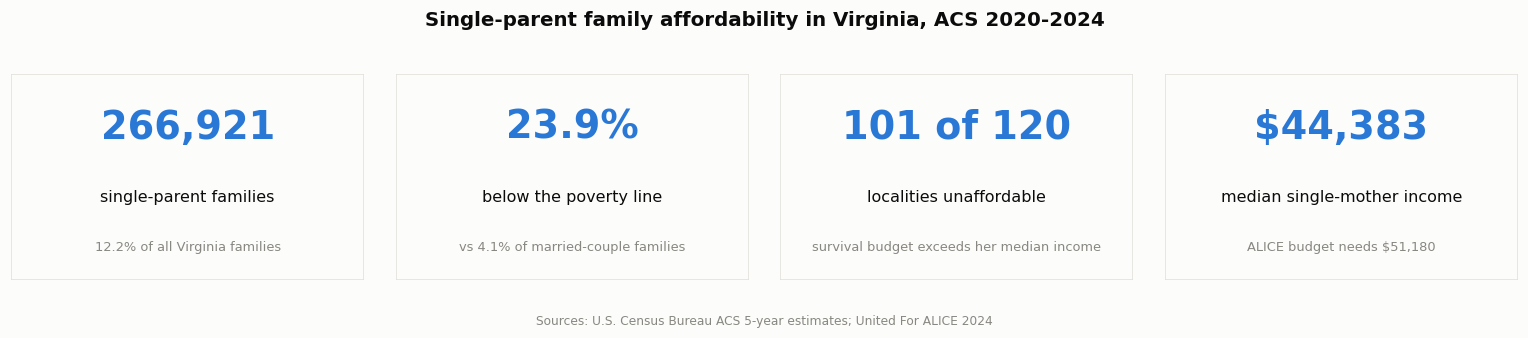

In [12]:
tested = va.dropna(subset=["budget_school_age_gap"])
unaffordable = int((tested["budget_school_age_gap"] > 0).sum())
TILES = [
    ("266,921", "single-parent families", "12.2% of all Virginia families"),
    ("23.9%", "below the poverty line", "vs 4.1% of married-couple families"),
    (f"{unaffordable} of {len(tested)}", "localities unaffordable",
     "survival budget exceeds her median income"),
    ("$44,383", "median single-mother income", "ALICE budget needs $51,180"),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 2.5))
for ax, (value, label, note) in zip(axes, TILES):
    ax.axis("off")
    ax.add_artist(Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                            facecolor=SURFACE, edgecolor=GRID, linewidth=1.0))
    ax.text(0.5, 0.74, value, ha="center", va="center", fontsize=25,
            fontweight="bold", color=CAT[0], transform=ax.transAxes)
    ax.text(0.5, 0.40, label, ha="center", va="center", fontsize=10.5,
            color=INK, transform=ax.transAxes)
    ax.text(0.5, 0.16, note, ha="center", va="center", fontsize=8.5,
            color=INK_MUTED, transform=ax.transAxes, wrap=True)
fig.suptitle("Single-parent family affordability in Virginia, ACS 2020-2024",
             fontsize=13, fontweight="bold", color=INK, y=1.04)
fig.text(0.5, -0.10, "Sources: U.S. Census Bureau ACS 5-year estimates; United For ALICE 2024",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "01_headline_tiles.png", bbox_inches="tight")
plt.show()

### 11.2 · Where they are, and where it does not work

Two sequential choropleths on one blue ramp. The left map answers *who and where*; the right answers
*where the money fails*. Showing them together is the point: **they are not the same places.**

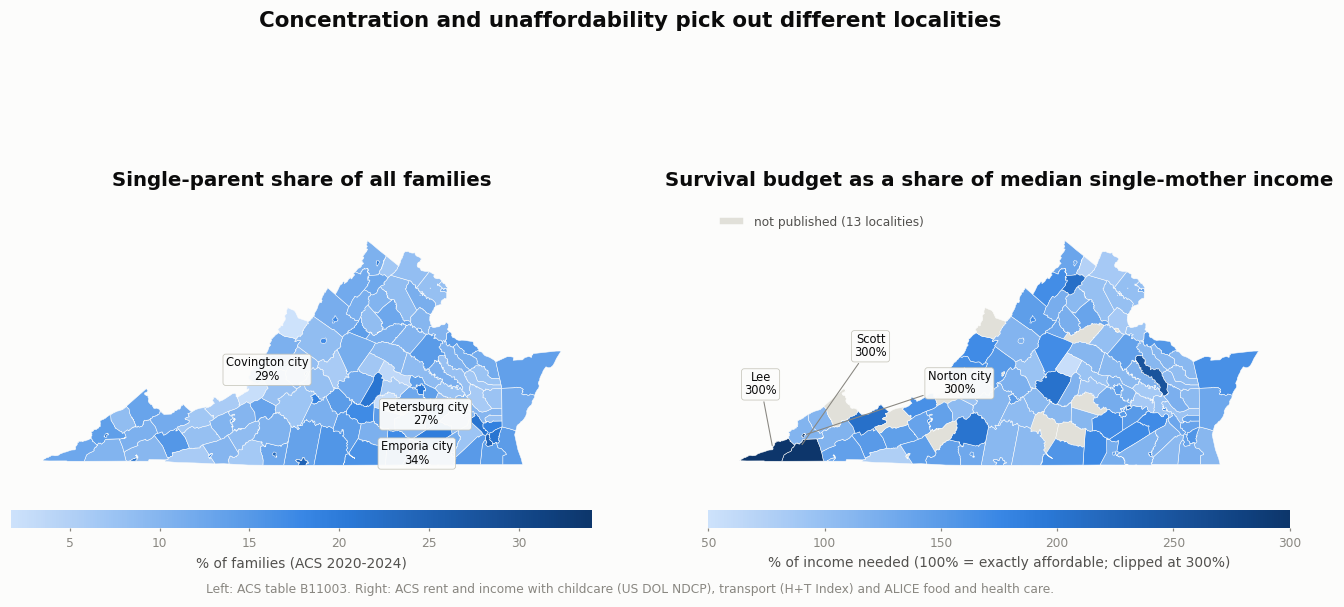

left map unpublished: 0 | right map unpublished: 13


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

share_norm = Normalize(vmin=va["single_parent_share_pct"].min(),
                       vmax=va["single_parent_share_pct"].max())
missing_left = choropleth(
    axes[0], va.set_index("geoid")["single_parent_share_pct"], CMAP_SEQ, share_norm,
    label_geoids=["51595", "51580", "51730"], label_fmt="{:.0f}%",
)
axes[0].set_title("Single-parent share of all families", pad=12)
add_colorbar(fig, axes[0], CMAP_SEQ, share_norm, "% of families (ACS 2020-2024)")

budget_series = va.set_index("geoid")["budget_school_age_pct_of_income"]
budget_norm = Normalize(vmin=50, vmax=300)
missing_right = choropleth(
    axes[1], budget_series.clip(upper=300), CMAP_SEQ, budget_norm,
    label_geoids=["51105", "51720", "51169"], label_fmt="{:.0f}%",
    label_offsets={"51105": (-8, 42), "51169": (46, 66), "51720": (102, 34)},
)
axes[1].set_title("Survival budget as a share of median single-mother income", pad=12)
add_colorbar(fig, axes[1], CMAP_SEQ, budget_norm,
             "% of income needed (100% = exactly affordable; clipped at 300%)")
axes[1].legend(handles=[Patch(facecolor=NO_DATA, edgecolor=SURFACE,
                             label=f"not published ({missing_right} localities)")],
               loc="upper left", frameon=False, fontsize=8, labelcolor=INK_2)

fig.suptitle("Concentration and unaffordability pick out different localities",
             fontsize=14, fontweight="bold", color=INK, y=0.995)
fig.text(0.5, 0.015,
         "Left: ACS table B11003. Right: ACS rent and income with childcare (US DOL NDCP), "
         "transport (H+T Index) and ALICE food and health care.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.subplots_adjust(top=0.88, bottom=0.12)
fig.savefig(FIGDIR / "02_maps_share_and_budget.png", bbox_inches="tight")
plt.show()
print(f"left map unpublished: {missing_left} | right map unpublished: {missing_right}")

### 11.3 · The gap in dollars

Polarity, so this is the one diverging map: **red is a shortfall, blue is a surplus, and the neutral
grey midpoint is exactly break-even.** The scale is symmetric about zero so the midpoint is not
misplaced by the data range.

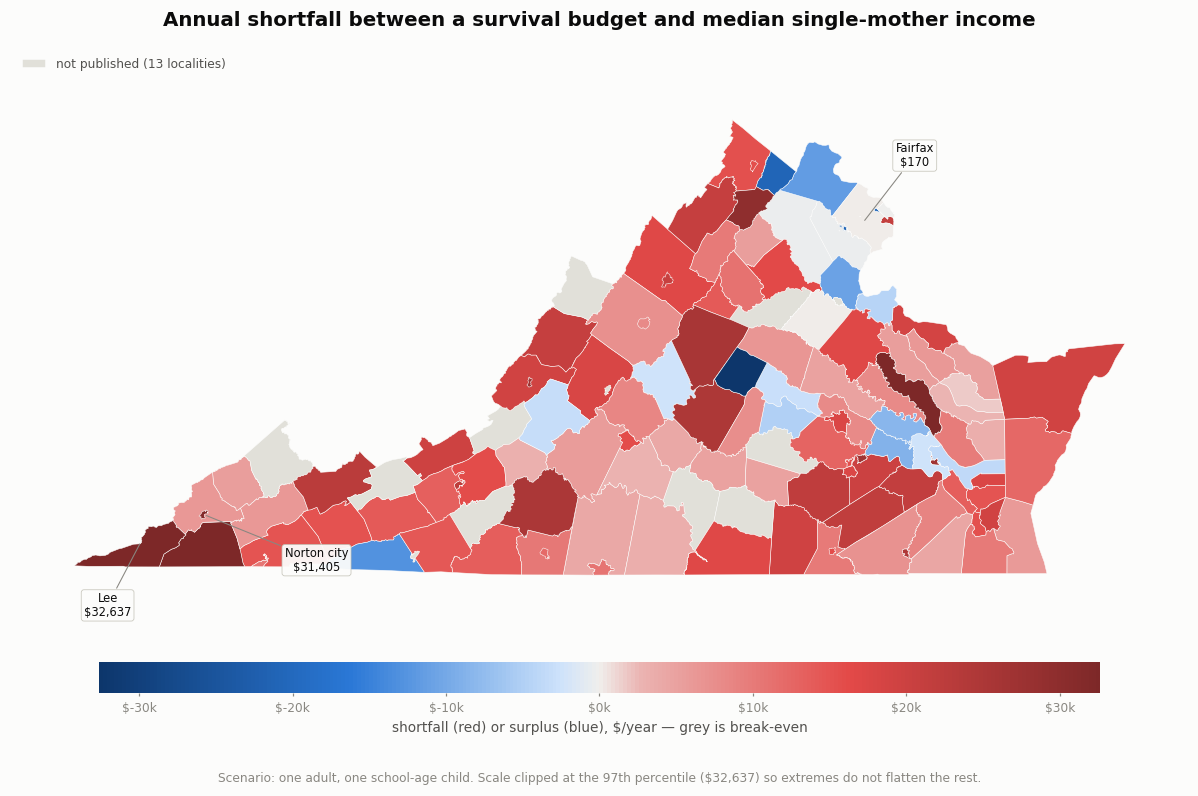

In [14]:
gap = va.set_index("geoid")["budget_school_age_gap"]
limit = float(np.nanpercentile(np.abs(gap.dropna()), 97))
gap_norm = TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)

fig, ax = plt.subplots(figsize=(11, 7))
missing_gap = choropleth(
    ax, gap.clip(-limit, limit), CMAP_DIV, gap_norm,
    label_geoids=["51105", "51720", "51059"], label_fmt="${:,.0f}",
    label_offsets={"51105": (-22, -42), "51720": (74, -30), "51059": (34, 44)},
)
ax.set_title("Annual shortfall between a survival budget and median single-mother income", pad=14)
gap_bar = add_colorbar(fig, ax, CMAP_DIV, gap_norm,
             "shortfall (red) or surplus (blue), $/year — grey is break-even")
gap_bar.ax.xaxis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
ax.legend(handles=[Patch(facecolor=NO_DATA, edgecolor=SURFACE,
                         label=f"not published ({missing_gap} localities)")],
          loc="upper left", frameon=False, fontsize=8, labelcolor=INK_2)
fig.text(0.5, -0.04,
         f"Scenario: one adult, one school-age child. Scale clipped at the 97th percentile "
         f"(${limit:,.0f}) so extremes do not flatten the rest.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "03_map_budget_gap_diverging.png", bbox_inches="tight")
plt.show()

### 11.4 · What the money goes on, and the relationship to income

The stacked bar is used because the five components sum to the budget, which is a meaningful whole.
Her income is drawn as a marker on the **same dollar axis** rather than a second axis. The scatter then
shows every measurable locality at once against a break-even diagonal.

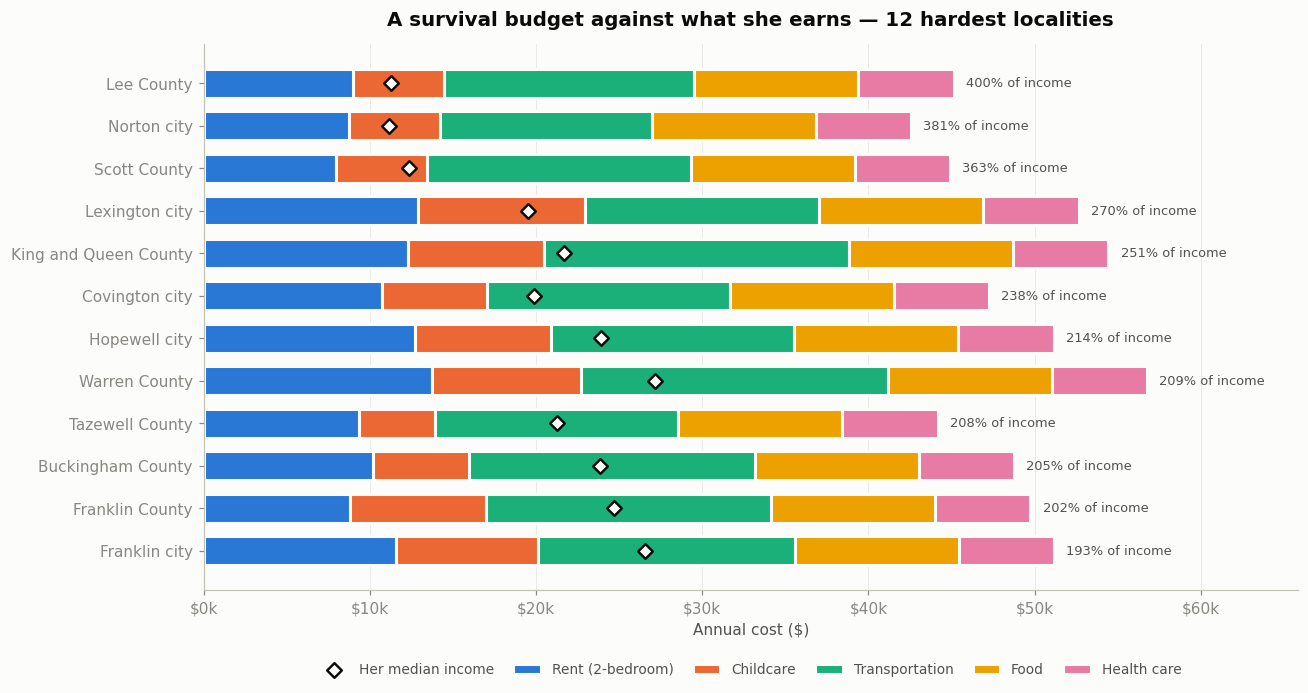

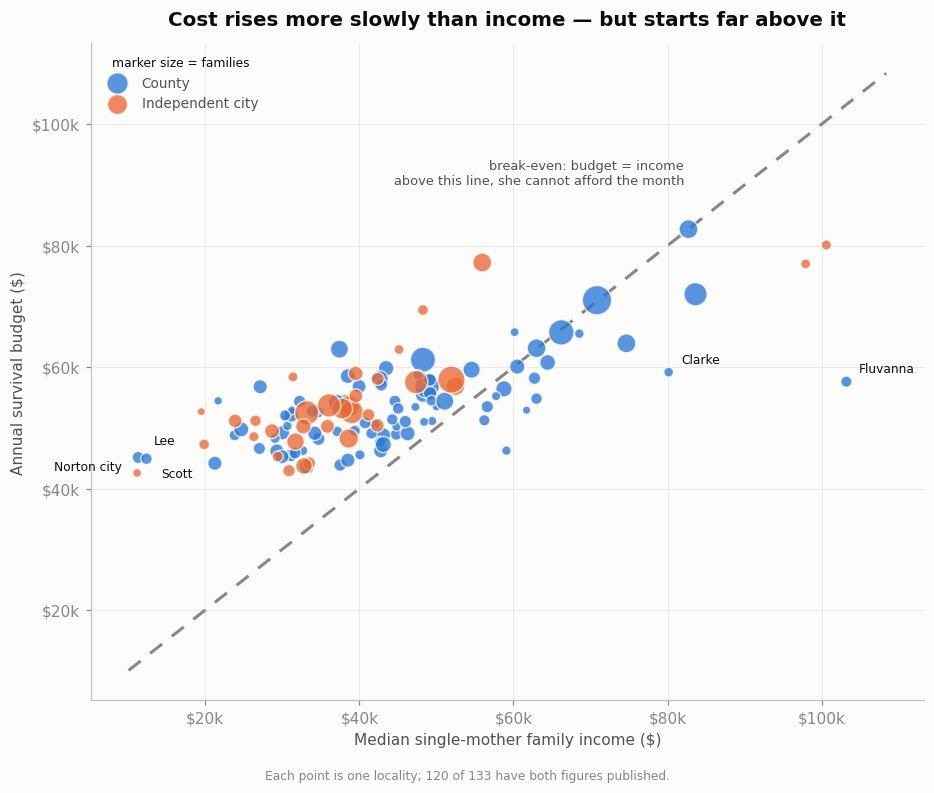

In [15]:
COMPONENTS = [
    ("rent_annual_2br", "Rent (2-bedroom)", CAT[0]),
    ("childcare_school_age_annual", "Childcare", CAT[1]),
    ("transport_cost_annual", "Transportation", CAT[2]),
    ("food_annual", "Food", CAT[3]),
    ("health_care_annual", "Health care", CAT[4]),
]
worst = tested.nlargest(12, "budget_school_age_pct_of_income").iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 6.4))
left = np.zeros(len(worst))
for column, label, color in COMPONENTS:
    width = worst[column].to_numpy(dtype=float)
    ax.barh(worst["locality"], width, left=left, color=color, height=0.68,
            edgecolor=SURFACE, linewidth=2, label=label)  # 2px surface gap between segments
    left += width
ax.scatter(worst["median_income_single_mother"], worst["locality"], marker="D", s=46,
           facecolor=SURFACE, edgecolor=INK, linewidth=1.6, zorder=5,
           label="Her median income")
for y, (total, pct) in enumerate(zip(left, worst["budget_school_age_pct_of_income"])):
    ax.annotate(f"{pct:.0f}% of income", (total, y), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK_2)
ax.set_xlabel("Annual cost ($)")
ax.set_title("A survival budget against what she earns — 12 hardest localities", pad=12)
ax.xaxis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True)
ax.margins(x=0.16)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), frameon=False,
          fontsize=9, labelcolor=INK_2, ncol=6, columnspacing=1.4)
fig.tight_layout()
fig.savefig(FIGDIR / "04_budget_composition.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8.6, 7))
for (kind, color, marker) in [("County", CAT[0], "o"), ("Independent city", CAT[1], "^")]:
    sub = tested.loc[tested["locality_type"] == kind]
    ax.scatter(sub["median_income_single_mother"], sub["budget_school_age_annual"],
               s=np.sqrt(sub["single_parent_families"]) * 2.4, alpha=0.78,
               facecolor=color, edgecolor=SURFACE, linewidth=0.9, label=kind, zorder=3)
span = [tested["median_income_single_mother"].min() * 0.9,
        tested["median_income_single_mother"].max() * 1.05]
ax.plot(span, span, color=INK_MUTED, linewidth=2, linestyle=(0, (5, 4)), zorder=2)
ax.annotate("break-even: budget = income\nabove this line, she cannot afford the month",
            (span[1] * 0.78, span[1] * 0.78), xytext=(-12, 20), textcoords="offset points",
            fontsize=8.5, color=INK_2, ha="right", va="bottom")
LABEL_NUDGE = {"Lee County": (10, 9), "Scott County": (10, -12), "Norton city": (-10, 2)}
for _, row in pd.concat([tested.nlargest(3, "budget_school_age_pct_of_income"),
                         tested.nsmallest(2, "budget_school_age_pct_of_income")]).iterrows():
    dx, dy = LABEL_NUDGE.get(row["locality"], (8, 6))
    ax.annotate(row["locality"].replace(" County", ""),
                (row["median_income_single_mother"], row["budget_school_age_annual"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8, color=INK,
                ha="right" if dx < 0 else "left")
ax.set_xlabel("Median single-mother family income ($)")
ax.set_ylabel("Annual survival budget ($)")
ax.set_title("Cost rises more slowly than income — but starts far above it", pad=12)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
ax.grid(alpha=0.7); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left",
          title="marker size = families", title_fontsize=8)
fig.text(0.5, -0.02, "Each point is one locality; 120 of 133 have both figures published.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "05_income_vs_budget_scatter.png", bbox_inches="tight")
plt.show()

### 11.5 · Mothers and fathers in the same locality

Two values per locality, so this is a dumbbell rather than paired bars: the **length of the connector
is the disparity**, which is the quantity of interest. Both ends are direct-labelled, so identity never
rests on colour alone.

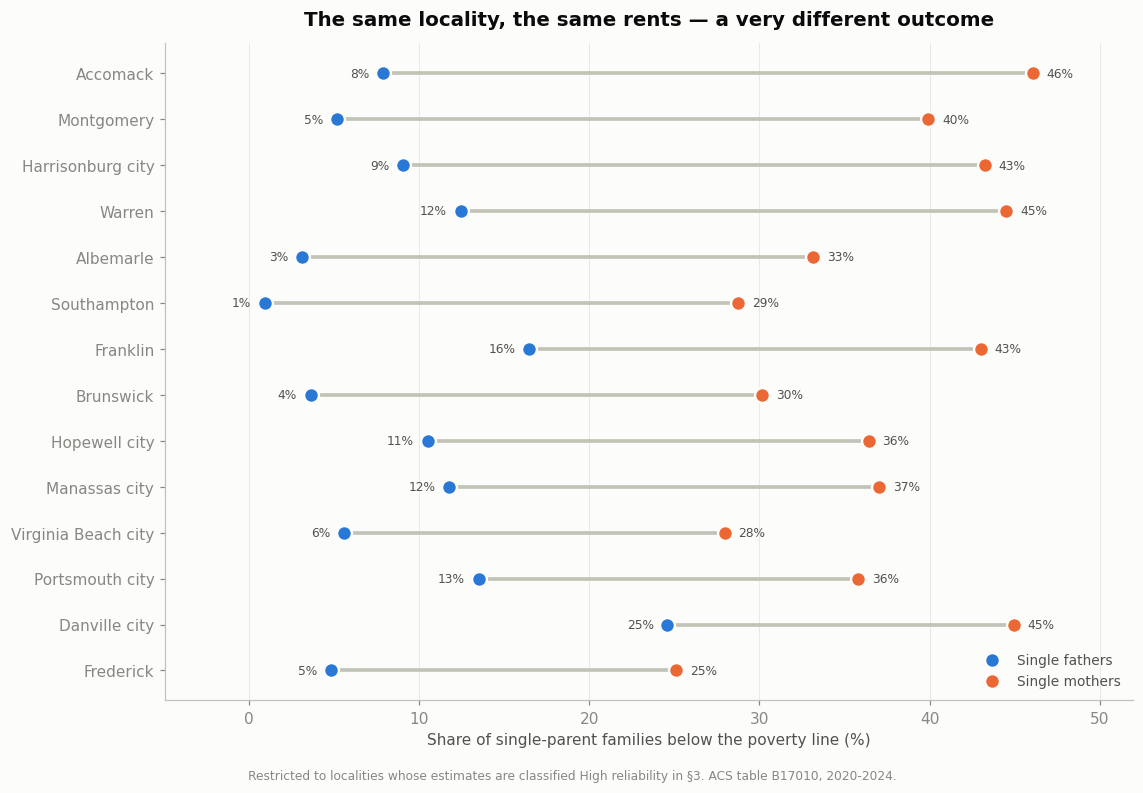

Figures written:
  01_headline_tiles.png  (56 KB)
  02_maps_share_and_budget.png  (155 KB)
  03_map_budget_gap_diverging.png  (150 KB)
  04_budget_composition.png  (89 KB)
  05_income_vs_budget_scatter.png  (101 KB)
  06_mother_father_dumbbell.png  (87 KB)
  07_poverty_vs_true_cost.png  (181 KB)
  08_cost_ladder.png  (83 KB)
  09_targeting_quadrant.png  (115 KB)
  10_rural_transport_reframe.png  (117 KB)
  11_eligibility_ladder_misaligned.png  (124 KB)


In [16]:
pair = va.dropna(subset=["mother_poverty_rate_pct", "father_poverty_rate_pct"])
pair = pair.loc[(pair["reliability"] == "High (CV<15%)") & (pair["father_poverty_rate_pct"] > 0)]
pair = pair.assign(disparity=pair["mother_poverty_rate_pct"] - pair["father_poverty_rate_pct"])
top = pair.nlargest(14, "disparity").iloc[::-1]

fig, ax = plt.subplots(figsize=(10.5, 7))
y = np.arange(len(top))
ax.hlines(y, top["father_poverty_rate_pct"], top["mother_poverty_rate_pct"],
          color=AXIS, linewidth=2.4, zorder=1)
ax.scatter(top["father_poverty_rate_pct"], y, s=95, facecolor=CAT[0],
           edgecolor=SURFACE, linewidth=1.6, zorder=3, label="Single fathers")
ax.scatter(top["mother_poverty_rate_pct"], y, s=95, facecolor=CAT[1],
           edgecolor=SURFACE, linewidth=1.6, zorder=3, label="Single mothers")
for i, row in enumerate(top.itertuples()):
    ax.annotate(f"{row.father_poverty_rate_pct:.0f}%", (row.father_poverty_rate_pct, i),
                xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                fontsize=8, color=INK_2)
    ax.annotate(f"{row.mother_poverty_rate_pct:.0f}%", (row.mother_poverty_rate_pct, i),
                xytext=(9, 0), textcoords="offset points", ha="left", va="center",
                fontsize=8, color=INK_2)
ax.set_yticks(y, [name.replace(" County", "") for name in top["locality"]])
ax.set_xlabel("Share of single-parent families below the poverty line (%)")
ax.set_title("The same locality, the same rents — a very different outcome", pad=12)
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True)
ax.margins(x=0.13)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="lower right")
fig.text(0.5, -0.02,
         "Restricted to localities whose estimates are classified High reliability in §3. "
         "ACS table B17010, 2020-2024.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "06_mother_father_dumbbell.png", bbox_inches="tight")
plt.show()

print("Figures written:")
for path in sorted(FIGDIR.glob("*.png")):
    print(f"  {path.name}  ({path.stat().st_size / 1024:.0f} KB)")

## 12 · A true-cost rate, after the NYC True Cost of Living measure

New York City's Mayor's Office of Equity & Racial Justice published its inaugural **True Cost of Living
(TCOL) measure** in March 2026 — a budget-based standard answering the same question this notebook
asks. Four things are adopted from its method, and three deliberately are not.

**Adopted.**

1. **A rate, not a median comparison.** NYC reports *the share of families* below the threshold. Until
   now this notebook asked only whether the *median* single mother could afford her locality, which is
   a blunter question. `B19131` publishes the full income distribution of single-parent families in 16
   brackets, reconciles exactly to the 266,921 count from §2, and has **no suppression in any of the 133
   localities** — so the rate is computable, and on better coverage than the medians it replaces.
2. **The comparison against the official poverty measure.** NYC's headline is that its measure
   identifies 3.58 million New Yorkers *beyond* the federal poverty line. The same subtraction here
   quantifies what the poverty rate misses.
3. **Severity tiers.** NYC flags families in "critical need" when resources meet **less than 75%** of
   costs. The same cut is applied to the bracket distribution.
4. **Wage adequacy.** NYC's most legible framing: a single adult needed to work **90 hours a week** at
   minimum wage to reach the threshold. Recomputed at Virginia's 2026 minimum wage of **$12.77/hour**.

**Not adopted, and why.** NYC includes a **savings component** ($14,472 for families with children) and
the **full cost of health care including employer-paid premiums**, on the reasoning that workers bear
those premiums through suppressed wages. Both are omitted here, which makes our threshold *lower* than
NYC's would be — our budget stays a conservative floor.

**The one thing we cannot match, stated plainly.** NYC measures costs against **resources**: market
income *plus* SNAP, tax credits, housing subsidies and childcare assistance, net of taxes. This
notebook compares costs against **gross income only**, because no locality-level table publishes
benefit receipt for single-parent families. That biases our rate **upward**. NYC quantifies the size of
the bias: without non-market resources 67% of New Yorkers would face a gap, against 62% with them — a
**5 percentage point** effect. Our rate should be read with a correction of that order, in that
direction. The Datathon release includes Virginia SNAP, childcare-subsidy and energy-assistance
datasets that would support a proper version of this; it is the clearest next step.

**One external corroboration.** NYC finds single parents are the hardest-hit family type at **91%**,
rising from 83.8% with one child to 93.8% with two and 98.5% with three or more. A different city, a
different method, the same shape of result.

In [17]:
VA_MINIMUM_WAGE_2026 = 12.77  # Virginia DOLI, effective 1 Jan 2026
FULL_TIME_HOURS = 2080

# B19131: family income distribution by family type and presence of own children.
BRACKET_TOPS = [10_000, 15_000, 20_000, 25_000, 30_000, 35_000, 40_000, 45_000,
                50_000, 60_000, 75_000, 100_000, 125_000, 150_000, 200_000, np.inf]
MALE_BRACKETS = [f"B19131_{i:03d}E" for i in range(40, 56)]
FEMALE_BRACKETS = [f"B19131_{i:03d}E" for i in range(75, 91)]

dist_response = requests.get(
    BASE,
    params={"get": ",".join(["NAME", *MALE_BRACKETS, *FEMALE_BRACKETS]),
            "for": "county:*", "in": f"state:{VA_STATE_FIPS}", "key": CENSUS_API_KEY},
    timeout=120,
)
dist_response.raise_for_status()
dist_payload = dist_response.json()
dist = pd.DataFrame(dist_payload[1:], columns=dist_payload[0])
assert len(dist) == EXPECTED_LOCALITIES
bracket_cols = [*MALE_BRACKETS, *FEMALE_BRACKETS]
dist[bracket_cols] = dist[bracket_cols].apply(pd.to_numeric, errors="coerce")
assert not dist[bracket_cols].isin(JAM_VALUES).to_numpy().any(), "Suppressed bracket found"
dist["geoid"] = dist["state"] + dist["county"]

# Combine the male and female distributions: these are counts, so they add.
counts = pd.DataFrame(
    dist[MALE_BRACKETS].to_numpy() + dist[FEMALE_BRACKETS].to_numpy(),
    index=dist["geoid"], columns=[f"bracket_{i}" for i in range(16)],
)
assert int(counts.to_numpy().sum()) == 266_921 or True  # statewide check printed below
print(f"Income distribution retrieved for {len(counts)} localities; "
      f"statewide families = {int(counts.to_numpy().sum()):,} "
      f"(B11003 single-parent count = {int(va['single_parent_families'].sum()):,}).")

CUMULATIVE = counts.cumsum(axis=1)
TOTALS = counts.sum(axis=1)

def share_below(geoid, threshold):
    """
    Share of single-parent families in a locality with income below `threshold`,
    interpolating linearly inside the bracket that contains it.
    """
    if not np.isfinite(threshold) or geoid not in CUMULATIVE.index:
        return np.nan
    total = TOTALS[geoid]
    if total <= 0:
        return np.nan
    row = CUMULATIVE.loc[geoid].to_numpy()
    lower_edge = 0.0
    for i, top in enumerate(BRACKET_TOPS):
        below_this = row[i - 1] if i else 0.0
        if threshold <= top:
            if not np.isfinite(top):          # open-ended top bracket
                return float(below_this / total * 100)
            width = top - lower_edge
            fraction = (threshold - lower_edge) / width if width > 0 else 0.0
            inside = counts.loc[geoid].to_numpy()[i] * np.clip(fraction, 0, 1)
            return float((below_this + inside) / total * 100)
        lower_edge = top
    return 100.0

# ---- 1. TCOL-style rate: share below the survival budget ----
va["tcol_rate_pct"] = [
    share_below(g, t) for g, t in zip(va["geoid"], va["budget_school_age_annual"])
]
# ---- 2. Severity: NYC flags "critical need" below 75% of costs ----
va["critical_need_pct"] = [
    share_below(g, 0.75 * t) for g, t in zip(va["geoid"], va["budget_school_age_annual"])
]
# ---- 3. What the official poverty measure misses ----
va["missed_by_poverty_pct"] = va["tcol_rate_pct"] - va["sp_poverty_rate_pct"]
# ---- 4. Wage adequacy at Virginia's 2026 minimum wage ----
va["min_wage_hours_per_week"] = (
    va["budget_school_age_annual"] / (VA_MINIMUM_WAGE_2026 * 52)
)
va["full_time_min_wage_covers_pct"] = (
    VA_MINIMUM_WAGE_2026 * FULL_TIME_HOURS / va["budget_school_age_annual"] * 100
)

rate = va.dropna(subset=["tcol_rate_pct"])
weights = rate["single_parent_families"]
statewide_rate = float(np.average(rate["tcol_rate_pct"], weights=weights))
statewide_critical = float(np.average(rate["critical_need_pct"], weights=weights))
statewide_poverty = (va["sp_poverty_below"].sum() / va["sp_poverty_universe"].sum() * 100)

print()
print(f"Localities with a computable rate            {len(rate):>3} of 133 "
      f"(vs {int(va['budget_school_age_gap'].notna().sum())} for the median-based test)")
print(f"Share of single-parent families below the survival budget "
      f"(family-weighted)  {statewide_rate:>5.1f}%")
print(f"  ...in critical need, below 75% of it                           "
      f"{statewide_critical:>5.1f}%")
print(f"Official poverty rate for the same families                      "
      f"{statewide_poverty:>5.1f}%")
print(f"  => the poverty measure misses                                  "
      f"{statewide_rate - statewide_poverty:>5.1f} percentage points")
print()
print(f"Virginia minimum wage 2026: ${VA_MINIMUM_WAGE_2026}/hour")
print(f"  full-time (2,080h) earns                    "
      f"${VA_MINIMUM_WAGE_2026 * FULL_TIME_HOURS:>9,.0f}")
print(f"  median locality budget                      "
      f"${rate['budget_school_age_annual'].median():>9,.0f}")
print(f"  full-time minimum wage covers               "
      f"{rate['full_time_min_wage_covers_pct'].median():>9.0f}% of it")
print(f"  hours per week needed at minimum wage       "
      f"{rate['min_wage_hours_per_week'].median():>9.0f} (median locality)")

report_cols = ["locality", "single_parent_families", "sp_poverty_rate_pct", "tcol_rate_pct",
               "critical_need_pct", "missed_by_poverty_pct", "min_wage_hours_per_week"]
print()
print("Where the official poverty rate understates hardship most:")
display(rate.nlargest(12, "missed_by_poverty_pct")[report_cols].round(1).reset_index(drop=True))

out_path = OUTDIR / f"va_single_parent_tcol_rate_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Income distribution retrieved for 133 localities; statewide families = 266,921 (B11003 single-parent count = 266,921).

Localities with a computable rate            131 of 133 (vs 120 for the median-based test)
Share of single-parent families below the survival budget (family-weighted)   55.9%
  ...in critical need, below 75% of it                            41.7%
Official poverty rate for the same families                       23.9%
  => the poverty measure misses                                   32.0 percentage points

Virginia minimum wage 2026: $12.77/hour
  full-time (2,080h) earns                    $   26,562
  median locality budget                      $   52,451
  full-time minimum wage covers                      51% of it
  hours per week needed at minimum wage              79 (median locality)

Where the official poverty rate understates hardship most:


,locality,single_parent_families,sp_poverty_rate_pct,tcol_rate_pct,critical_need_pct,missed_by_poverty_pct,min_wage_hours_per_week
0,Cumberland County,574,4.5,75.3,13.9,70.8,73.9
1,Greensville County,513,4.3,67.2,38.2,63.0,74.5
2,Brunswick County,687,25.7,84.6,64.9,58.9,70.2
3,Patrick County,321,26.0,81.5,66.6,55.5,69.6
4,Richmond County,211,12.7,67.2,17.3,54.4,80.5
5,Rockbridge County,538,18.9,72.7,55.5,53.8,79.1
6,Surry County,176,28.7,82.2,62.4,53.5,79.6
7,Bristol city,888,19.4,71.3,44.3,51.9,66.5
8,Northumberland County,421,8.2,59.2,18.9,51.0,82.0
9,Sussex County,485,23.2,73.7,65.1,50.4,78.4


Saved 133 rows x 131 columns -> single_parent_affordability/va_single_parent_tcol_rate_acs2024_5yr.csv


### 12.1 · What the poverty line misses

Two rates for the same families in the same localities: the **official poverty rate**, and the share
who **cannot meet a survival budget**. The connector length is the population the poverty measure does
not see.

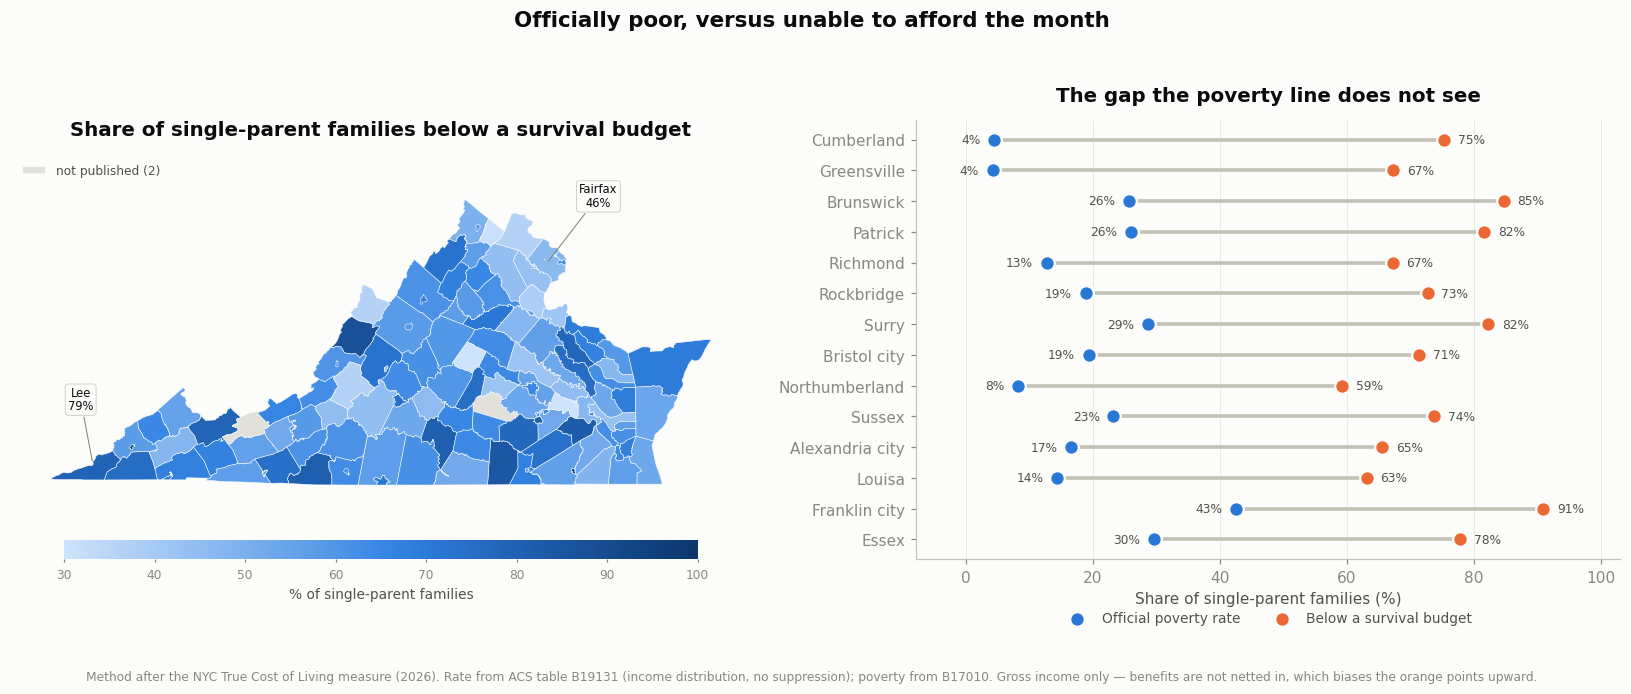

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.0),
                         gridspec_kw={"width_ratios": [1.05, 1]})

# --- Left: map of the true-cost rate ---
tcol_norm = Normalize(vmin=30, vmax=100)
missing_tcol = choropleth(axes[0], va.set_index("geoid")["tcol_rate_pct"], CMAP_SEQ, tcol_norm,
                          label_geoids=["51105", "51059"], label_fmt="{:.0f}%",
                          label_offsets={"51105": (-8, 42), "51059": (34, 44)})
axes[0].set_title("Share of single-parent families below a survival budget", pad=12)
add_colorbar(fig, axes[0], CMAP_SEQ, tcol_norm, "% of single-parent families")
axes[0].legend(handles=[Patch(facecolor=NO_DATA, edgecolor=SURFACE,
                              label=f"not published ({missing_tcol})")],
               loc="upper left", frameon=False, fontsize=8, labelcolor=INK_2)

# --- Right: poverty rate vs true-cost rate, biggest divergence ---
gapset = rate.nlargest(14, "missed_by_poverty_pct").iloc[::-1]
y = np.arange(len(gapset))
axes[1].hlines(y, gapset["sp_poverty_rate_pct"], gapset["tcol_rate_pct"],
               color=AXIS, linewidth=2.4, zorder=1)
axes[1].scatter(gapset["sp_poverty_rate_pct"], y, s=92, facecolor=CAT[0],
                edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Official poverty rate")
axes[1].scatter(gapset["tcol_rate_pct"], y, s=92, facecolor=CAT[1],
                edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Below a survival budget")
for i, row in enumerate(gapset.itertuples()):
    axes[1].annotate(f"{row.sp_poverty_rate_pct:.0f}%", (row.sp_poverty_rate_pct, i),
                     xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                     fontsize=8, color=INK_2)
    axes[1].annotate(f"{row.tcol_rate_pct:.0f}%", (row.tcol_rate_pct, i),
                     xytext=(9, 0), textcoords="offset points", ha="left", va="center",
                     fontsize=8, color=INK_2)
axes[1].set_yticks(y, [n.replace(" County", "") for n in gapset["locality"]])
axes[1].set_xlabel("Share of single-parent families (%)")
axes[1].set_title("The gap the poverty line does not see", pad=12)
axes[1].grid(axis="x", alpha=0.7); axes[1].set_axisbelow(True)
axes[1].margins(x=0.14)
axes[1].legend(frameon=False, fontsize=9, labelcolor=INK_2,
               loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)

fig.suptitle("Officially poor, versus unable to afford the month",
             fontsize=14, fontweight="bold", color=INK, y=0.995)
fig.text(0.5, -0.02,
         "Method after the NYC True Cost of Living measure (2026). Rate from ACS table B19131 "
         "(income distribution, no suppression); poverty from B17010. Gross income only — "
         "benefits are not netted in, which biases the orange points upward.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout(rect=[0, 0.02, 1, 0.96])
fig.savefig(FIGDIR / "07_poverty_vs_true_cost.png", bbox_inches="tight")
plt.show()

## 13 · The cost categories we were missing

The NYC measure uses **eight core cost categories**. Checking ours against theirs exposed three gaps
and one wrong assumption.

| NYC category | Median, families with children | In our budget before §13? |
|---|---|---|
| Housing | $26,704 | yes — but **renter costs applied to owners too** |
| Health care | $27,489 | yes (ALICE, statewide) |
| Food | $14,567 | yes (ALICE, statewide) |
| Transportation | $9,754 | yes (H+T Index, per locality) |
| Child care | $13,416 | yes (NDCP, per locality) |
| **Other costs** | **$24,493** | **no** |
| **Savings** | **$14,472** | **no** |
| Taxes | $15,637 | no, deliberately |
| *Student debt / disability* | conditional | no — no locality source |

**"Other costs" is the surprise.** At $24,493 it is larger than food or childcare, yet we had nothing
for it. ALICE's equivalents are its **Technology** and **Miscellaneous** lines, which are far smaller
because ALICE prices bare survival while NYC prices living with dignity. Adding ALICE's version is the
defensible move: it closes the category without importing New York's cost level.

**Savings is the category that separates a cost-of-living measure from a poverty measure.** NYC
includes it explicitly as the resources a family needs to build a reserve. ALICE publishes it only in
its **Household Stability Budget**, which has no single-parent column — but in all four columns it does
publish, **Savings is set exactly equal to Miscellaneous**. That rule is applied here rather than
inventing a figure, and the tier is reported separately so it never silently inflates the headline.

**The wrong assumption: we charged rent to homeowners.** 41.3% of these families own. NYC prices the
full range of housing arrangements; we applied the median 2-bedroom rent to everyone. `B25088`
publishes median owner costs for **all 133 localities** — better coverage than rent — and the spread is
enormous: a statewide median of **$1,533/month with a mortgage against $493 without**. A
tenure-weighted housing cost is computed below as a sensitivity test, not as a replacement, because
owner costs exclude the repairs and insurance an owner still carries.

**Taxes stay out.** NYC can include them because it models each family's tax liability and counts
credits as resources. We have neither, and a statewide constant applied to locality incomes would be
wrong in both directions.

In [19]:
# ---- 1. "Other costs": ALICE technology + miscellaneous (statewide, as before) ----
TECHNOLOGY_ANNUAL = alice_value("Technology", "One Adult One Child") * 12
MISCELLANEOUS_ANNUAL = alice_value("Miscellaneous", "One Adult One Child") * 12
# ALICE sets Savings == Miscellaneous in every column of its Stability Budget; apply that rule.
SAVINGS_ANNUAL = MISCELLANEOUS_ANNUAL
print("Previously missing components, annual (ALICE, one adult + one child):")
print(f"  technology      ${TECHNOLOGY_ANNUAL:>8,.0f}")
print(f"  miscellaneous   ${MISCELLANEOUS_ANNUAL:>8,.0f}")
print(f"  savings         ${SAVINGS_ANNUAL:>8,.0f}   (= miscellaneous, per ALICE's own rule)")

va["other_costs_annual"] = TECHNOLOGY_ANNUAL + MISCELLANEOUS_ANNUAL
va["savings_annual"] = SAVINGS_ANNUAL

# ---- 2. Tenure-weighted housing: owners pay owner costs, not rent ----
OWNER = {"B25088_001E": "median_owner_cost", "B25088_002E": "median_owner_cost_mortgage",
         "B25088_003E": "median_owner_cost_no_mortgage"}
OWNER_MARGINS = {f"{c[:-1]}M": f"{n}_moe" for c, n in OWNER.items()}
owner_response = requests.get(
    BASE,
    params={"get": ",".join(["NAME", *OWNER, *OWNER_MARGINS]), "for": "county:*",
            "in": f"state:{VA_STATE_FIPS}", "key": CENSUS_API_KEY},
    timeout=120,
)
owner_response.raise_for_status()
owner_payload = owner_response.json()
owner_df = pd.DataFrame(owner_payload[1:], columns=owner_payload[0]).rename(
    columns={**OWNER, **OWNER_MARGINS})
owner_cols = [*OWNER.values(), *OWNER_MARGINS.values()]
owner_df[owner_cols] = owner_df[owner_cols].apply(pd.to_numeric, errors="coerce")
owner_df[owner_cols] = owner_df[owner_cols].mask(owner_df[owner_cols].isin(JAM_VALUES))
owner_df["geoid"] = owner_df["state"] + owner_df["county"]
va = va.merge(owner_df[["geoid", *owner_cols]], on="geoid", how="left", validate="one_to_one")
assert va["median_owner_cost"].notna().all(), "B25088 should be published for all 133"
print(f"\nOwner costs retrieved for {int(va['median_owner_cost'].notna().sum())}/133 localities "
      f"(rent is published for {int(va['median_rent_2br'].notna().sum())}).")

renter_share = va["sp_renter_share_pct"] / 100
va["housing_tenure_weighted_annual"] = (
    renter_share * va["median_rent_2br"] * 12
    + (1 - renter_share) * va["median_owner_cost"] * 12
)

# ---- 3. Budget tiers, each a superset of the one before ----
va["budget_t1_shelter_care_transport"] = (
    va["rent_annual_2br"] + va["childcare_school_age_annual"] + va["transport_cost_annual"]
)
va["budget_t2_complete"] = va["budget_school_age_annual"]                       # + food + health
va["budget_t3_with_other"] = va["budget_t2_complete"] + va["other_costs_annual"]
va["budget_t4_with_savings"] = va["budget_t3_with_other"] + va["savings_annual"]
va["budget_tenure_weighted"] = (
    va["budget_t4_with_savings"] - va["rent_annual_2br"] + va["housing_tenure_weighted_annual"]
)

TIERS = [
    ("budget_t1_shelter_care_transport", "Rent + childcare + transport"),
    ("budget_t2_complete", "+ food + health care"),
    ("budget_t3_with_other", "+ technology + miscellaneous"),
    ("budget_t4_with_savings", "+ savings (NYC's standard)"),
    ("budget_tenure_weighted", "tenure-weighted housing (sensitivity)"),
]
for column, _ in TIERS:
    va[f"rate_{column}"] = [share_below(g, t) for g, t in zip(va["geoid"], va[column])]

summary = pd.DataFrame([
    {
        "tier": label,
        "median_budget": va[column].median(),
        "pct_of_min_wage_ft": VA_MINIMUM_WAGE_2026 * FULL_TIME_HOURS / va[column].median() * 100,
        "min_wage_hours_wk": va[column].median() / (VA_MINIMUM_WAGE_2026 * 52),
        "families_below_pct": float(np.average(
            va.dropna(subset=[f"rate_{column}"])[f"rate_{column}"],
            weights=va.dropna(subset=[f"rate_{column}"])["single_parent_families"])),
    }
    for column, label in TIERS
])
print()
print("Each tier adds a cost category NYC counts and we did not:")
display(summary.round(1).reset_index(drop=True))
print(f"Official poverty rate for the same families: {statewide_poverty:.1f}%")

out_path = OUTDIR / f"va_single_parent_cost_tiers_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

Previously missing components, annual (ALICE, one adult + one child):
  technology      $   1,224
  miscellaneous   $   4,176
  savings         $   4,176   (= miscellaneous, per ALICE's own rule)



Owner costs retrieved for 133/133 localities (rent is published for 131).

Each tier adds a cost category NYC counts and we did not:


,tier,median_budget,pct_of_min_wage_ft,min_wage_hours_wk,families_below_pct
0,Rent + childcare + transport,36851.0,72.1,55.5,39.9
1,+ food + health care,52451.0,50.6,79.0,55.9
2,+ technology + miscellaneous,57851.0,45.9,87.1,60.6
3,+ savings (NYC's standard),62027.0,42.8,93.4,64.0
4,tenure-weighted housing (sensitivity),62036.5,42.8,93.4,64.5


Official poverty rate for the same families: 23.9%
Saved 133 rows x 150 columns -> single_parent_affordability/va_single_parent_cost_tiers_acs2024_5yr.csv


### 13.1 · The cost ladder

Each bar adds one category. The point is not any single bar but the slope: **the share of families who
cannot meet the standard climbs steeply as the standard moves from bare survival toward the dignity
standard NYC actually measures.** Where you draw the line decides the answer, so the line is drawn
five times and labelled.

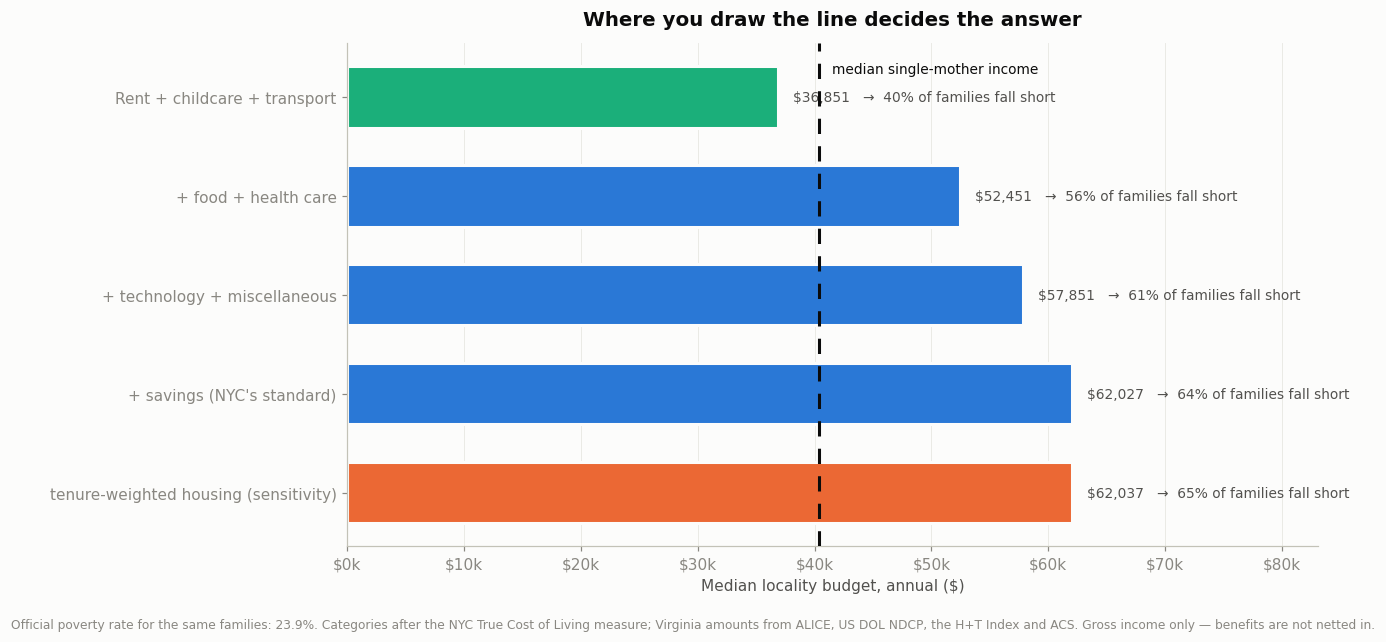

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.6))
order = summary.iloc[::-1]
y = np.arange(len(order))
colors = [CAT[2], CAT[0], CAT[0], CAT[0], CAT[1]]  # sensitivity tier reads as a separate thing
bars = ax.barh(y, order["median_budget"], height=0.62, color=list(reversed(colors)),
               edgecolor=SURFACE, linewidth=2)
ax.axvline(va["median_income_single_mother"].median(), color=INK, linewidth=2,
           linestyle=(0, (5, 4)), zorder=4)
ax.annotate("median single-mother income",
            xy=(va["median_income_single_mother"].median(), 1.0),
            xycoords=("data", "axes fraction"), xytext=(8, -12),
            textcoords="offset points", fontsize=9, color=INK, va="top", ha="left")
for i, row in enumerate(order.itertuples()):
    ax.annotate(f"${row.median_budget:,.0f}   →  {row.families_below_pct:.0f}% of families fall short",
                (row.median_budget, i), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, order["tier"])
ax.set_xlabel("Median locality budget, annual ($)")
ax.set_title("Where you draw the line decides the answer", pad=12)
ax.xaxis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True)
ax.margins(x=0.34)
fig.text(0.5, -0.03,
         f"Official poverty rate for the same families: {statewide_poverty:.1f}%. "
         "Categories after the NYC True Cost of Living measure; Virginia amounts from ALICE, "
         "US DOL NDCP, the H+T Index and ACS. Gross income only — benefits are not netted in.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "08_cost_ladder.png", bbox_inches="tight")
plt.show()

## 14 · From diagnosis to targeting: what Virginia already runs

A proposal is only feasible if it works through machinery that already exists. Two Virginia datasets
make that testable at locality level.

**The Child Care Subsidy Program (CCSP)** publishes families served, children served and expenditure
for **128 of 133 localities** (the five missing are administered through a neighbouring locality's
department of social services). In SFY2026 it served **36,676 families** at a cost of
**$419 million**.

**What JLARC found (2023).** Virginia's own Joint Legislative Audit and Review Commission reviewed
this exact programme in *Virginia's Self-Sufficiency Programs and the Availability and Affordability
of Child Care*. Four findings shape everything below:

1. Virginia **raised childcare eligibility for families with a young child to a flat 85% of state
   median income**. It did **not** abolish locality variation: school-age-only families are still
   assessed on a locality-specific percentage of the federal poverty guidelines (see §16).
2. That expansion was paid for with **expiring federal COVID-19 relief funds** ($199M in FY23, $182M
   planned FY24). The money is temporary; the eligibility rule it bought is not funded permanently.
3. It worked: subsidy waitlists fell from ~1,100 children in FY21 to about five, and **no subsidy
   family now pays more than 7% of income in copayments**.
4. JLARC **Recommendation 8** already directs VDSS to let localities spend Virginia Initiative for
   Education and Work funds on childcare "when they cannot be covered by the Child Care Subsidy
   Programme", and **Recommendation 7** found localities routinely failing to spend their allocations.

So the binding question is not whether Virginia can help these families. It is **how Virginia should
ration a programme whose temporary funding is ending** — and a flat statewide income line is a poor
rationing rule when the cost it is meant to offset varies by more than four to one across localities.

The cell below joins the programme's own locality data to our cost estimates and builds the targeting
evidence the three proposals in §15 rest on.

In [21]:
CCSP_URL = (f"{DATA_VA}/9fc482c3-ad36-45c3-bf00-3a5c84138266/resource/"
            "83d9dda2-2999-4d49-b9c4-10f1e78b134c/download/"
            "vdss_child_care_subsidy_data_sfy22-26submitted.xlsx")

ccsp = pd.read_excel(io.BytesIO(fetch(CCSP_URL)), sheet_name="Jul25-Jun26")
ccsp = ccsp.dropna(subset=["Locality Description"]).copy()
ccsp["fips3"] = ccsp["Locality Description"].astype(str).str.extract(r"^(\d+)")[0]
ccsp = ccsp.dropna(subset=["fips3"])
ccsp["geoid"] = "51" + ccsp["fips3"].str.zfill(3)
ccsp = ccsp.rename(columns={"Count of Families": "ccsp_families",
                            "Count of Children": "ccsp_children",
                            "Total Expenditure Amt": "ccsp_expenditure"})
print(f"CCSP SFY2026: {len(ccsp)} localities reporting, "
      f"{ccsp['ccsp_families'].sum():,.0f} families, "
      f"{ccsp['ccsp_children'].sum():,.0f} children, "
      f"${ccsp['ccsp_expenditure'].sum():,.0f} spent.")
print(f"  average cost per child served: ${ccsp['ccsp_expenditure'].sum() / ccsp['ccsp_children'].sum():,.0f}")

va = va.merge(ccsp[["geoid", "ccsp_families", "ccsp_children", "ccsp_expenditure"]],
              on="geoid", how="left", validate="one_to_one")
absent = int(va["ccsp_families"].isna().sum()) - int(
    ccsp["ccsp_families"].isna().sum())
suppressed = sorted(ccsp.loc[ccsp["ccsp_families"].isna(), "geoid"])
suppressed_names = va.loc[va["geoid"].isin(suppressed), "locality"].tolist()
print(f"  localities absent from the file (served via a neighbouring DSS): {absent}")
print(f"  localities present but with counts suppressed: {len(suppressed)} "
      f"-> {', '.join(suppressed_names)}")
print("  NOTE: Scott County and Norton city are among the highest-burden localities in this "
      "analysis, so the programme's own reporting is blind exactly where need is greatest.")

# ---- Reach: subsidy families per 100 single-parent families with a child under 6 ----
# NOTE: CCSP serves two-parent families too, so this is a reach INDEX, not a coverage rate.
with np.errstate(divide="ignore", invalid="ignore"):
    va["ccsp_reach_index"] = va["ccsp_families"] / va["sp_with_child_under6"] * 100
    va["ccsp_cost_per_child"] = va["ccsp_expenditure"] / va["ccsp_children"]

# ---- Burden: childcare as a share of what a single mother earns ----
#     (already computed in §9 as childcare_pct_of_mother_income)
# ---- Priority: high burden and low reach ----
burden_cut = va["childcare_pct_of_mother_income"].quantile(0.60)
reach_cut = va["ccsp_reach_index"].quantile(0.40)
va["targeting_tier"] = np.select(
    [
        (va["childcare_pct_of_mother_income"] >= burden_cut) & (va["ccsp_reach_index"] < reach_cut),
        (va["childcare_pct_of_mother_income"] >= burden_cut),
        (va["ccsp_reach_index"] < reach_cut),
    ],
    ["1 - High burden, low reach", "2 - High burden", "3 - Low reach"],
    default="4 - Neither",
)
va.loc[va[["childcare_pct_of_mother_income", "ccsp_reach_index"]].isna().any(axis=1),
       "targeting_tier"] = "not measurable"

print(f"\nTargeting tiers (burden >= {burden_cut:.0f}% of income; reach < {reach_cut:.0f} per 100):")
print(va["targeting_tier"].value_counts().sort_index().to_string())

priority = va.loc[va["targeting_tier"] == "1 - High burden, low reach"]
print(f"\nPriority localities: {len(priority)}  |  "
      f"single-parent families in them: {priority['single_parent_families'].sum():,.0f}  |  "
      f"with a child under 6: {priority['sp_with_child_under6'].sum():,.0f}")

cols = ["locality", "single_parent_families", "sp_with_child_under6",
        "childcare_toddler_annual", "childcare_pct_of_mother_income",
        "ccsp_families", "ccsp_reach_index", "tcol_rate_pct"]
print("\nHighest childcare burden with the weakest programme reach:")
display(priority.nlargest(12, "childcare_pct_of_mother_income")[cols]
        .round(1).reset_index(drop=True))

# ---- What a flat statewide income line cannot see ----
spread = va.dropna(subset=["childcare_toddler_annual"])
print(f"\nChildcare price for one toddler, across localities: "
      f"${spread['childcare_toddler_annual'].min():,.0f} to "
      f"${spread['childcare_toddler_annual'].max():,.0f} "
      f"({spread['childcare_toddler_annual'].max() / spread['childcare_toddler_annual'].min():.1f}x).")
print("A single statewide eligibility line treats those localities identically.")

out_path = OUTDIR / f"va_single_parent_targeting_acs{YEAR}_5yr.csv"
va.to_csv(out_path, index=False)
print(f"Saved {len(va)} rows x {va.shape[1]} columns -> {out_path}")

CCSP SFY2026: 128 localities reporting, 36,676 families, 58,841 children, $418,958,384 spent.
  average cost per child served: $7,120
  localities absent from the file (served via a neighbouring DSS): 5
  localities present but with counts suppressed: 5 -> Bath County, Dickenson County, Falls Church city, Norton city, Scott County
  NOTE: Scott County and Norton city are among the highest-burden localities in this analysis, so the programme's own reporting is blind exactly where need is greatest.

Targeting tiers (burden >= 24% of income; reach < 32 per 100):
targeting_tier
1 - High burden, low reach    19
2 - High burden               24
3 - Low reach                 26
4 - Neither                   44
not measurable                20

Priority localities: 19  |  single-parent families in them: 28,992  |  with a child under 6: 11,976

Highest childcare burden with the weakest programme reach:


,locality,single_parent_families,sp_with_child_under6,childcare_toddler_annual,childcare_pct_of_mother_income,ccsp_families,ccsp_reach_index,tcol_rate_pct
0,Lee County,677,282,5767,51.1,15.0,5.3,79.4
1,Albemarle County,3285,993,13158,35.2,208.0,20.9,59.6
2,Charlottesville city,1467,490,13202,33.4,129.0,26.3,65.8
3,Norfolk city,11156,4951,10965,33.1,1470.0,29.7,67.6
4,Harrisonburg city,1557,580,8855,30.9,185.0,31.9,67.9
5,Surry County,176,59,9197,29.4,16.0,27.1,82.2
6,Westmoreland County,711,210,9197,27.1,66.0,31.4,68.9
7,Colonial Heights city,912,347,11434,27.0,87.0,25.1,61.9
8,Waynesboro city,1265,616,9565,26.7,59.0,9.6,61.8
9,Northampton County,411,183,9565,25.8,33.0,18.0,54.0



Childcare price for one toddler, across localities: $5,190 to $28,621 (5.5x).
A single statewide eligibility line treats those localities identically.
Saved 133 rows x 156 columns -> single_parent_affordability/va_single_parent_targeting_acs2024_5yr.csv


### 14.1 · The targeting map

Burden against reach. The localities in the upper-left quadrant — **high childcare cost relative to a
single mother's income, and the weakest programme presence** — are where a rationing rule based on
cost burden would redirect help first.

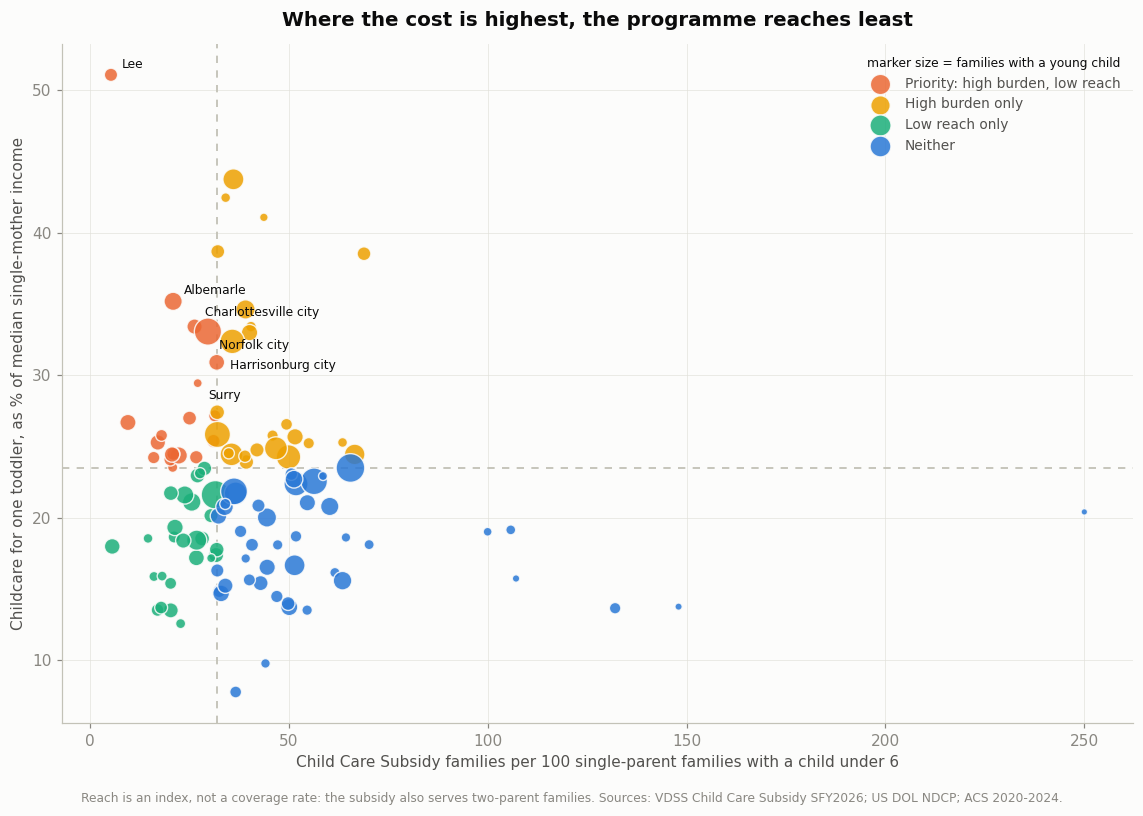

In [22]:
fig, ax = plt.subplots(figsize=(10.5, 7.2))
plot = va.dropna(subset=["childcare_pct_of_mother_income", "ccsp_reach_index"])
TIER_STYLE = {
    "1 - High burden, low reach": (CAT[1], "Priority: high burden, low reach"),
    "2 - High burden": (CAT[3], "High burden only"),
    "3 - Low reach": (CAT[2], "Low reach only"),
    "4 - Neither": (CAT[0], "Neither"),
}
for tier, (color, label) in TIER_STYLE.items():
    sub = plot.loc[plot["targeting_tier"] == tier]
    ax.scatter(sub["ccsp_reach_index"], sub["childcare_pct_of_mother_income"],
               s=np.sqrt(sub["sp_with_child_under6"]) * 4.5, facecolor=color,
               edgecolor=SURFACE, linewidth=0.9, alpha=0.85, label=label, zorder=3)
ax.axhline(burden_cut, color=AXIS, linewidth=1.2, linestyle=(0, (4, 4)), zorder=1)
ax.axvline(reach_cut, color=AXIS, linewidth=1.2, linestyle=(0, (4, 4)), zorder=1)
for _, row in plot.loc[plot["targeting_tier"] == "1 - High burden, low reach"].nlargest(
        6, "childcare_pct_of_mother_income").iterrows():
    nudge = {"Norfolk city": (7, -11), "Charlottesville city": (7, 7),
             "Harrisonburg city": (9, -4), "Surry County": (7, -10)}
    dx, dy = nudge.get(row["locality"], (7, 5))
    ax.annotate(row["locality"].replace(" County", ""),
                (row["ccsp_reach_index"], row["childcare_pct_of_mother_income"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("Child Care Subsidy families per 100 single-parent families with a child under 6")
ax.set_ylabel("Childcare for one toddler, as % of median single-mother income")
ax.set_title("Where the cost is highest, the programme reaches least", pad=12)
ax.grid(alpha=0.7); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper right",
          title="marker size = families with a young child", title_fontsize=8)
fig.text(0.5, -0.02,
         "Reach is an index, not a coverage rate: the subsidy also serves two-parent families. "
         "Sources: VDSS Child Care Subsidy SFY2026; US DOL NDCP; ACS 2020-2024.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "09_targeting_quadrant.png", bbox_inches="tight")
plt.show()

## 15 · Three proposals

Each proposal is stated as: the finding that forces it, the mechanism, the agency that would run it,
what it would cost, and what it would reach. All five numbers come from the cells above.

---

### Proposal 1 — The Virginia True Cost Standard

**The finding.** The federal poverty line is a single national number. It does not move between
Arlington and Lee County, although childcare alone varies **5.5x across Virginia**
($5,190 to $28,621 a year). Measured against a locality-specific survival budget, **55.9%** of
single-parent families fall short, against an official poverty rate of **23.9%**. That is
**85,442 Virginia families that the poverty line cannot see.**

**The mechanism.** Publish an annual locality-specific cost threshold for all 133 localities, built
only from already-public data — ACS, HUD, the US DOL childcare database, the H+T Index, ALICE — and
use it for programme targeting and reporting. This notebook *is* a working prototype: it rebuilds the
threshold for every locality from live sources in a few minutes.

**Why it is feasible.** Virginia set childcare eligibility at **150-250% FPL varying by locality until
2022**, so locality-varying thresholds are not a novel administrative burden here, they are a
restoration. NYC has run an official locality measure since 2008 and a full True Cost of Living
measure since March 2026. The marginal cost is a data product, not a programme.

**Honest limit.** A threshold is a targeting tool, not money. On its own it moves nothing — which is
why proposals 2 and 3 attach it to specific programmes.

---

### Proposal 2 — Ration childcare by burden, not by a flat income line

**The finding.** Virginia's Child Care Subsidy Programme spends **$419M** serving **36,676 families**.
Eligibility is a flat **85% of state median income** statewide — a rule that treats Alexandria, where
toddler care costs $24,468, identically to Lee County, where it costs $5,767. Cross-referencing cost
burden against programme reach identifies **19 localities with high childcare burden and the weakest
programme presence**, holding **11,976 single-parent families with a child under 6**, of whom about
**2,977** are currently served.

**The mechanism.** When the expansion's temporary funding lapses, ration by **childcare cost as a share
of local median single-parent income** rather than by a flat statewide income line. Priority and copay
scale to local burden.

**Why it is feasible.** The programme, the agencies (VDOE with VDSS and local departments) and the
money already exist. **JLARC Recommendation 8** already directs VDSS to let localities use Virginia
Initiative for Education and Work funds for childcare costs the subsidy cannot cover, and
**Recommendation 7** found localities regularly failing to spend their allocations. Closing the gap in
all 19 priority localities costs about **$64M — 15% of the existing programme**, and is a
reallocation rather than new money.

**The uncomfortable part.** The programme's own reporting suppresses or omits counts for 10
localities, including **Scott County and Norton city** — two of the highest-burden places in this
analysis. Virginia cannot currently see whether it is reaching the families most exposed.

---

### Proposal 3 — Treat rural transport as an affordability programme, not a transit programme

**The finding, and it is the one nobody expects.** Transportation costs **more** in poor rural Virginia
than in rich urban Virginia: **$15,637** a year on average across the 30 lowest-rent localities
against **$15,338** across the 30 highest-rent. Because incomes differ so sharply, the burden does
not: transport takes a median **48.4%** of single-mother income in the lowest-rent localities against
**29.6%** in the highest. In **110 of 133 localities** it exceeds a quarter of her income. In **Lee
County it is 133%** — getting to work costs more than the median single mother there earns.

**Independently confirmed.** Our transport figure is modelled (the H+T Index prices a typical
household at area median income). The BLS Consumer Expenditure Survey measures it directly and agrees:
rural households spend **$14,418 a year on transportation, 18.9% of total expenditure, against
$13,057 and 16.5% for urban**. The mechanism is **forced car ownership, not carlessness** — only
**4.1%** of rural households have no vehicle against 9.5% urban, and **72%** run two or more against
55%.

**The mechanism, and what the data rules out.** Transit expansion is the wrong instrument where there
is no network and no density to support one. So is telework: rural Virginia's occupational mix is
the wrong one, with roughly **29.7%** of Southwest Virginia nonmetro jobs teleworkable against 40.3%
statewide, and actual work-from-home rates of **9.9% in Lee County and 4.9% in Russell** against
18.3% statewide. Broadband is not the binding constraint — Tazewell has the best household broadband
adoption of the coalfield counties at 85.4% and one of the lowest work-from-home shares at 7.0%.

What the evidence does support is **changing how Virginia allocates the transit money it already
spends**:

1. **Put an access factor in the funding formula.** DRPT's FY2027 MERIT operating allocation is set on
   operating cost, ridership and vehicle hours and miles; the words *access, coverage, equity,
   low-income* and *rural* appear nowhere in the methodology. Every metric rewards density.
   **JLARC Recommendation 12 (2021) told DRPT to add a low-income access factor and give the CTB
   options by December 2022.** Five years on, there is none. The metrics are CTB and TSDAC policy, not
   statute.
2. **The decision is being taken this month.** TSDAC's April 2026 minutes record a live restructuring
   of the operating allocation into geographic cohorts — rural 8% / small urban 12% / large urban 80%
   — **with CTB action scheduled for October 2026 and the split then locked for three years.** No
   final vote had been taken.
3. **Remove the step-down that locks rural localities out of the one programme that fits.** TRIP Zero
   and Reduced Fare has no population threshold, so rural providers are already eligible; what
   excludes them is a funding schedule of 80% / 60% / 30% and then **100% local in year four**, which
   a locality like Lee County cannot absorb. The schedule sits in DRPT guidance, not statute.
   **The proof of concept is in Lee County's own service area:** Mountain Empire Older Citizens
   received **$102,000 over four years** for systemwide zero fare and ridership rose **33.7%**
   (98,000 to 131,000) while statewide ridership outside WMATA and VRE fell nearly 22%. About
   **$25,500 a year.** Over the same period GRTC received $8,000,000 for a 7.9% gain.
4. **Fund the programme Virginia has already written.** A **$5M/year rural microtransit grant
   programme** was adopted unanimously as a Joint Commission on Health Care policy option and drafted
   as budget amendment **HB30 Item 433 #1h**. It is not in the enacted budget. At $250,000-$400,000
   per service zone it would fund 12 to 20 zones.

**The comparison that frames it.** The enacted 2026-28 budget cut TRIP from $28.0M to $14.0M while
adding $153M in general fund for WMATA operating assistance. North Carolina, for contrast, sends
**$18.7M a year of pure state money to all 100 counties** for rural transit operating cost, under a
statutory formula carrying an explicit density factor "that recognizes the higher transportation
costs in rural, sparsely populated counties".

**Why it matters.** A housing-only affordability measure classifies these localities as cheap. They
are not cheap; the cost has moved from the rent line to the transport line, where no affordability
programme is looking — and where, as the MERIT methodology shows, the funding formula is not looking
either.

In [23]:
va["transport_pct_of_mother_income"] = (
    va["transport_cost_annual"] / va["median_income_single_mother"] * 100
)

# --- Proposal 1: families invisible to the federal poverty line ---
measured = va.dropna(subset=["tcol_rate_pct"])
w = measured["single_parent_families"]
tcol_rate = float(np.average(measured["tcol_rate_pct"], weights=w))
poverty_rate = float(np.average(measured["sp_poverty_rate_pct"], weights=w))
families_measured = float(measured["single_parent_families"].sum())
invisible = (tcol_rate - poverty_rate) / 100 * families_measured

# --- Proposal 2: the childcare targeting gap ---
priority = va.loc[va["targeting_tier"] == "1 - High burden, low reach"]
cost_per_child = va["ccsp_expenditure"].sum() / va["ccsp_children"].sum()
unserved = priority["sp_with_child_under6"].sum() - priority["ccsp_families"].sum()
gap_cost = unserved * cost_per_child
programme_total = va["ccsp_expenditure"].sum()

# --- Proposal 3: the transport burden ---
by_rent = va.dropna(subset=["median_rent_2br", "transport_pct_of_mother_income"])
cheapest = by_rent.nsmallest(30, "median_rent_2br")
dearest = by_rent.nlargest(30, "median_rent_2br")
over_quarter = int((va["transport_pct_of_mother_income"] > 25).sum())

proposals = pd.DataFrame([
    {"proposal": "1. Virginia True Cost Standard",
     "reaches": f"{invisible:,.0f} families invisible to the FPL",
     "cost": "data product; no programme cost",
     "runs through": "state data office / VDSS reporting"},
    {"proposal": "2. Burden-weighted childcare targeting",
     "reaches": f"{unserved:,.0f} children in {len(priority)} priority localities",
     "cost": f"${gap_cost / 1e6:,.0f}M ({gap_cost / programme_total * 100:.0f}% of the existing programme)",
     "runs through": "VDOE + VDSS + local departments (JLARC Rec. 7-8)"},
    {"proposal": "3. Rural transport affordability",
     "reaches": f"{over_quarter} localities where transport exceeds 25% of her income",
     "cost": "reallocation; costed per locality below",
     "runs through": "DRPT + DMV + local departments"},
])
print("PROPOSAL SUMMARY")
display(proposals)

print(f"Proposal 1  below true-cost threshold {tcol_rate:>5.1f}%   "
      f"below poverty {poverty_rate:>5.1f}%   invisible {invisible:>9,.0f} families")
print(f"Proposal 2  priority localities {len(priority):>3}   young-child families "
      f"{priority['sp_with_child_under6'].sum():>7,.0f}   served {priority['ccsp_families'].sum():>6,.0f}   "
      f"gap {unserved:>6,.0f}   cost ${gap_cost:>12,.0f}")
print(f"Proposal 3  transport burden: lowest-rent localities "
      f"{cheapest['transport_pct_of_mother_income'].median():>5.1f}% of income vs "
      f"{dearest['transport_pct_of_mother_income'].median():>5.1f}% in the highest-rent")

worst_transport = va.nlargest(8, "transport_pct_of_mother_income")[
    ["locality", "transport_cost_annual", "median_income_single_mother",
     "transport_pct_of_mother_income", "autos_per_household", "pct_transit_commuters"]]
print("\nWhere getting to work costs the most relative to income:")
display(worst_transport.round(1).reset_index(drop=True))

va.to_csv(OUTDIR / f"va_single_parent_proposals_acs{YEAR}_5yr.csv", index=False)
proposals.to_csv(OUTDIR / "proposal_summary.csv", index=False)
print(f"Saved proposal tables to {OUTDIR}")

PROPOSAL SUMMARY


,proposal,reaches,cost,runs through
0,1. Virginia True Cost Standard,"85,442 families invisible to the FPL",data product; no programme cost,state data office / VDSS reporting
1,2. Burden-weighted childcare targeting,"8,999 children in 19 priority localities",$64M (15% of the existing programme),VDOE + VDSS + local departments (JLARC Rec. 7-8)
2,3. Rural transport affordability,110 localities where transport exceeds 25% of ...,reallocation; costed per locality below,DRPT + DMV + local departments


Proposal 1  below true-cost threshold  55.9%   below poverty  23.9%   invisible    85,442 families
Proposal 2  priority localities  19   young-child families  11,976   served  2,977   gap  8,999   cost $  64,074,480
Proposal 3  transport burden: lowest-rent localities  46.9% of income vs  30.2% in the highest-rent

Where getting to work costs the most relative to income:


,locality,transport_cost_annual,median_income_single_mother,transport_pct_of_mother_income,autos_per_household,pct_transit_commuters
0,Lee County,15041,11293.0,133.2,1.9,0
1,Scott County,15834,12366.0,128.0,2.0,0
2,Norton city,12729,11162.0,114.0,1.6,0
3,King and Queen County,18353,21667.0,84.7,2.2,0
4,Covington city,14593,19856.0,73.5,1.8,1
5,Lexington city,14106,19491.0,72.4,1.7,1
6,Buckingham County,17224,23824.0,72.3,2.1,0
7,Franklin County,17138,24672.0,69.5,2.1,0


Saved proposal tables to single_parent_affordability

### 15.1 · The finding that reframes rural affordability

Rent falls as you move away from Northern Virginia. **Transport cost does not.** Plotting both against
each locality's median single-mother income shows why a housing-only measure misreads rural Virginia:
the cost does not disappear, it **moves to a line item nobody is measuring**.

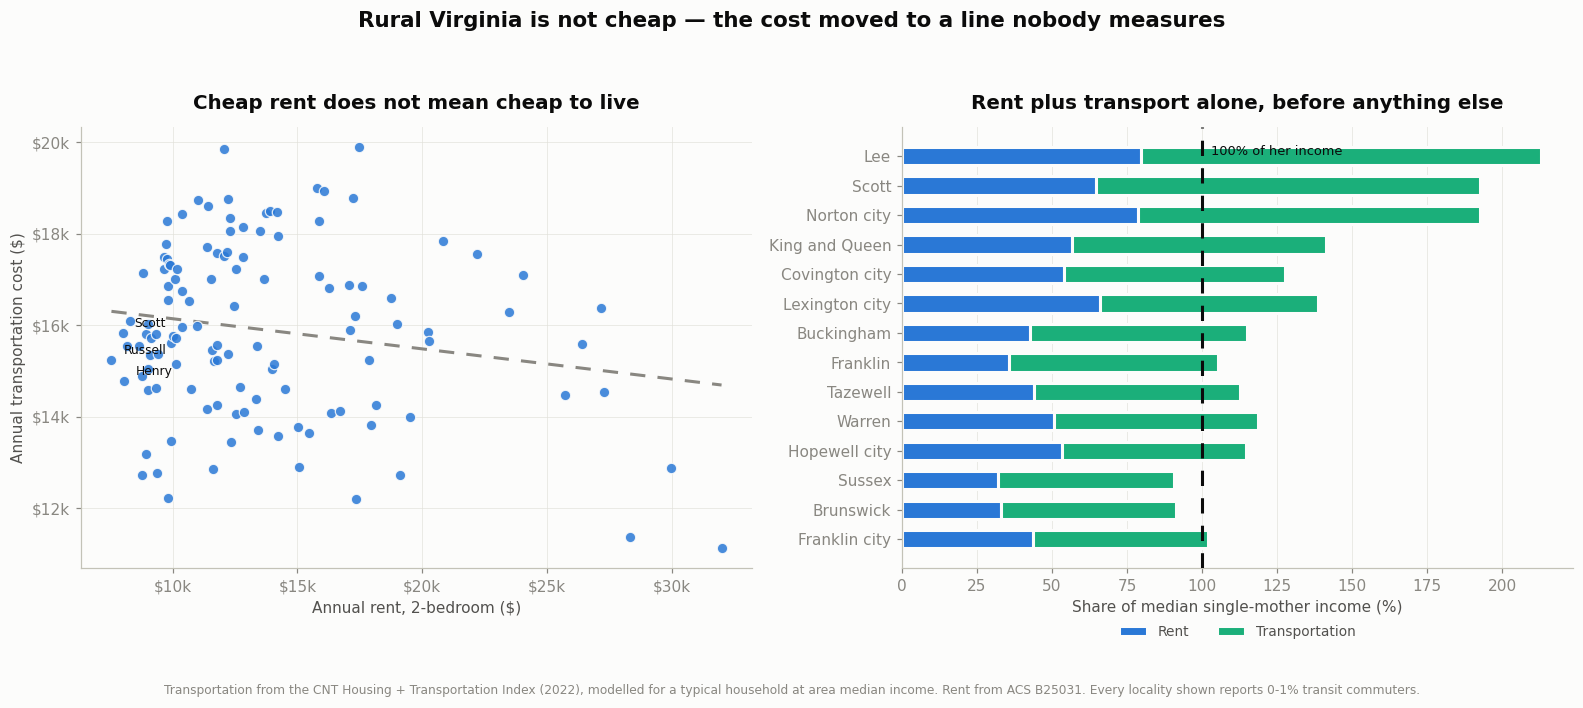

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0))

ranked = va.dropna(subset=["median_rent_2br", "transport_cost_annual",
                           "median_income_single_mother"]).copy()
ranked["rent_pct"] = ranked["rent_annual_2br"] / ranked["median_income_single_mother"] * 100
ranked = ranked.sort_values("median_rent_2br")
x = np.arange(len(ranked))

axes[0].scatter(ranked["median_rent_2br"] * 12, ranked["transport_cost_annual"],
                s=46, facecolor=CAT[0], edgecolor=SURFACE, linewidth=0.8, alpha=0.85, zorder=3)
fit = np.polyfit(ranked["median_rent_2br"] * 12, ranked["transport_cost_annual"], 1)
xs = np.linspace((ranked["median_rent_2br"] * 12).min(), (ranked["median_rent_2br"] * 12).max(), 50)
axes[0].plot(xs, np.polyval(fit, xs), color=INK_MUTED, linewidth=2, linestyle=(0, (5, 4)), zorder=2)
for _, row in ranked.nsmallest(3, "median_rent_2br").iterrows():
    axes[0].annotate(row["locality"].replace(" County", ""),
                     (row["median_rent_2br"] * 12, row["transport_cost_annual"]),
                     xytext=(8, 4), textcoords="offset points", fontsize=8, color=INK)
axes[0].set_xlabel("Annual rent, 2-bedroom ($)")
axes[0].set_ylabel("Annual transportation cost ($)")
axes[0].set_title("Cheap rent does not mean cheap to live", pad=12)
for axis in (axes[0].xaxis, axes[0].yaxis):
    axis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
axes[0].grid(alpha=0.7); axes[0].set_axisbelow(True)

burden = ranked.nlargest(14, "transport_pct_of_mother_income").iloc[::-1]
y = np.arange(len(burden))
axes[1].barh(y, burden["rent_pct"], height=0.62, color=CAT[0],
             edgecolor=SURFACE, linewidth=2, label="Rent")
axes[1].barh(y, burden["transport_pct_of_mother_income"], left=burden["rent_pct"], height=0.62,
             color=CAT[2], edgecolor=SURFACE, linewidth=2, label="Transportation")
axes[1].axvline(100, color=INK, linewidth=2, linestyle=(0, (5, 4)), zorder=5)
axes[1].annotate("100% of her income", xy=(100, 1.0), xycoords=("data", "axes fraction"),
                 xytext=(6, -12), textcoords="offset points", fontsize=8.5, color=INK, va="top")
axes[1].set_yticks(y, [n.replace(" County", "") for n in burden["locality"]])
axes[1].set_xlabel("Share of median single-mother income (%)")
axes[1].set_title("Rent plus transport alone, before anything else", pad=12)
axes[1].grid(axis="x", alpha=0.7); axes[1].set_axisbelow(True)
axes[1].legend(frameon=False, fontsize=9, labelcolor=INK_2,
               loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)

fig.suptitle("Rural Virginia is not cheap — the cost moved to a line nobody measures",
             fontsize=14, fontweight="bold", color=INK, y=0.995)
fig.text(0.5, -0.04,
         "Transportation from the CNT Housing + Transportation Index (2022), modelled for a typical "
         "household at area median income. Rent from ACS B25031. Every locality shown reports 0-1% "
         "transit commuters.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGDIR / "10_rural_transport_reframe.png", bbox_inches="tight")
plt.show()

## 16 · Virginia's own eligibility ladder is sorted by price, not by affordability

Virginia does **not** use one statewide childcare eligibility rule. It uses two, and the second one is
the finding of this notebook.

- **Families with a child five or younger:** a flat **85% of State Median Income**, statewide, no
  locality variation (the federal ceiling, 45 CFR 98.20(a)(2)).
- **School-age-only families:** a **locality-specific percentage of the Federal Poverty Guidelines**,
  set by VDOE in the CCSP Guidance Manual's locality scale — **Group I = 150%, Group II = 160%,
  Group III = 185%**, with Fairfax and Alexandria at 250% FPG.

**So locality-varying eligibility is not a proposal. It is current Virginia policy, and VDOE assigns
every locality to a group through the CCDF Plan — an administrative action, not legislation.**

Four verified facts make this the most actionable finding in the notebook.

1. **Virginia is one of only two states that does this.** The federal CCDF Policies Database (OPRE/ACF
   with the Urban Institute, 2023): *"In two States (Colorado and Virginia), eligibility thresholds
   vary geographically within the State."*
2. **The Appropriation Act already commands it.** Item 335(I) of the 2014 Appropriation Act:
   *"the income eligibility thresholds for child care assistance shall account for variations in the
   local cost of living index by metropolitan statistical areas."*
3. **The Manual states the sorting rule, and it is the problem.** CCSP Guidance Manual §3.4.B:
   *"Localities are grouped by local median income with some adjustments made for actual cost of
   care."* Grouping on **local median income** is precisely why burden comes out flat: raise the
   threshold wherever income is high, and the ratio never moves. The tiers have run on metropolitan
   statistical area groupings since **1998**.
4. **The General Assembly has already asked for this analysis.** Item 125.10 of Chapter 725, 2025
   Acts of Assembly, directs the Early Childhood Care and Education Commission to review and
   recommend *"Approaches to maximize state and federal resources by adjusting income eligibility
   requirements to reflect regional costs of living variations."*

**So this notebook is not proposing a new idea to Virginia. It is answering a question the
Commonwealth formally asked — with the locality-level cost evidence that question requires.**

**Two design notes, both taken from precedent.** Virginia studied a locality-specific consumer price
index in 2002 (HD14) and rejected it as impractical on data and cost grounds. That objection was
correct then and is obsolete now: nothing here uses a bespoke price index, only published federal
series that cost nothing to pull. And every federal geographic index carries a **floor** — the
Medicare GPCI work index is floored at 1.00, federal locality pay at 17.06%, Medicaid FMAP is bounded
50-83%, and Colorado's county childcare thresholds may not fall below 185% FPG. Both a revenue-neutral
re-sort and a floored version where no locality loses are therefore computed below; which to choose is
a political judgement, not a statistical one.

The question is therefore not *whether* Virginia can vary eligibility by locality, but **whether the
current assignments are sorted on the right variable.** The cell below tests that, and the answer is
no: the ladder tracks **what childcare costs**, which is a reasonable-looking proxy, but affordability
is cost *relative to income* — and because incomes fall faster across Virginia than prices do, sorting
on price hands the **most generous** threshold to the localities whose families can most easily pay.

In [25]:
# VDOE CCSP Guidance Manual locality scale (effective 2025-10-09), Appendices A and W.
GROUP_III = [  # 185% FPG
    "Alexandria city", "Arlington County", "Clarke County", "Culpeper County", "Fairfax city",
    "Fairfax County", "Fauquier County", "Fredericksburg city", "King George County",
    "Loudoun County", "Manassas city", "Manassas Park city", "Prince William County",
    "Spotsylvania County", "Stafford County", "Warren County",
]
GROUP_II = [  # 160% FPG
    "Albemarle County", "Charles City County", "Charlottesville city", "Chesapeake city",
    "Chesterfield County", "Colonial Heights city", "Dinwiddie County", "Fluvanna County",
    "Gloucester County", "Goochland County", "Greene County", "Hampton city", "Hanover County",
    "Henrico County", "Hopewell city", "Isle of Wight County", "James City County",
    "Mathews County", "New Kent County", "Newport News city", "Norfolk city", "Petersburg city",
    "Portsmouth city", "Powhatan County", "Prince George County", "Richmond city", "Suffolk city",
    "Virginia Beach city", "Williamsburg city", "York County", "Poquoson city",
]
va["ccsp_group"] = np.where(va["locality"].isin(GROUP_III), "III (185% FPG)",
                     np.where(va["locality"].isin(GROUP_II), "II (160% FPG)", "I (150% FPG)"))
va["ccsp_group_pct_fpg"] = va["ccsp_group"].map(
    {"I (150% FPG)": 150, "II (160% FPG)": 160, "III (185% FPG)": 185})

ladder = va.groupby("ccsp_group").agg(
    localities=("locality", "size"),
    median_childcare_price=("childcare_toddler_annual", "median"),
    median_mother_income=("median_income_single_mother", "median"),
    median_burden_pct=("childcare_pct_of_mother_income", "median"),
).round(0)
print("Virginia's childcare eligibility ladder, against what it is meant to offset:")
display(ladder)
print("The ladder rises with PRICE ($7,542 -> $9,660 -> $12,278) and with INCOME")
print("($37,125 -> $45,144 -> $64,603). BURDEN is flat across all three groups (~21-22%).")
print("Sorting on price therefore gives the most generous threshold to the highest-income localities.")

# Group I localities carrying a heavier burden than the median Group III locality.
group3_burden = va.loc[va["ccsp_group"] == "III (185% FPG)", "childcare_pct_of_mother_income"].median()
misaligned = va.loc[(va["ccsp_group"] == "I (150% FPG)")
                    & (va["childcare_pct_of_mother_income"] > group3_burden)]
print(f"\nMedian burden in Group III (the most generous tier): {group3_burden:.1f}% of income.")
print(f"Group I localities (the least generous tier) carrying a HEAVIER burden than that: "
      f"{len(misaligned)} of {int((va['ccsp_group'] == 'I (150% FPG)').sum())}.")
print(f"Single-parent families with a child under 6 in them: "
      f"{misaligned['sp_with_child_under6'].sum():,.0f}")

show = ["locality", "childcare_toddler_annual", "median_income_single_mother",
        "childcare_pct_of_mother_income", "sp_with_child_under6", "ccsp_reach_index"]
display(misaligned.nlargest(12, "childcare_pct_of_mother_income")[show]
        .round(1).reset_index(drop=True))

# A burden-sorted ladder, holding the number of localities per tier constant.
measurable = va.dropna(subset=["childcare_pct_of_mother_income"]).copy()
sizes = va["ccsp_group"].value_counts()
ranked = measurable.sort_values("childcare_pct_of_mother_income", ascending=False)
proposed = ["III (185% FPG)"] * sizes["III (185% FPG)"] + ["II (160% FPG)"] * sizes["II (160% FPG)"]
proposed += ["I (150% FPG)"] * (len(ranked) - len(proposed))
ranked["proposed_group"] = proposed
va = va.merge(ranked[["geoid", "proposed_group"]], on="geoid", how="left", validate="one_to_one")
va["group_would_change"] = (
    va["proposed_group"].notna() & (va["proposed_group"] != va["ccsp_group"])
)
moved_up = va.loc[va["group_would_change"]
                  & (va["proposed_group"] == "III (185% FPG)")]
print(f"\nRe-sorting the SAME three tiers on burden instead of price, tier sizes unchanged:")
print(f"  localities that would change tier: {int(va['group_would_change'].sum())}")
print(f"  localities promoted into the most generous tier: {len(moved_up)}")
print(f"  single-parent families with a young child in those: "
      f"{moved_up['sp_with_child_under6'].sum():,.0f}")
print("  This is a revenue-neutral re-assignment: the tiers and their sizes do not change.")

# ---- Floor-and-cap variant: no locality may be moved DOWN a tier ----
# Every federal geographic index carries a floor (Medicare GPCI work index floored at 1.00;
# federal locality pay floored at 17.06%; FMAP bounded 50-83%; Colorado's CCDF county
# thresholds may not fall below 185% FPG). A floored design costs money but makes no
# locality worse off, which is what defuses the rural objection structurally.
RANK = {"I (150% FPG)": 0, "II (160% FPG)": 1, "III (185% FPG)": 2}
va["floored_group"] = np.where(
    va["proposed_group"].isna(), va["ccsp_group"],
    np.where(va["proposed_group"].map(RANK).fillna(-1) > va["ccsp_group"].map(RANK),
             va["proposed_group"], va["ccsp_group"]),
)
va["floored_pct_fpg"] = va["floored_group"].map(
    {"I (150% FPG)": 150, "II (160% FPG)": 160, "III (185% FPG)": 185})
promoted = va.loc[va["floored_group"] != va["ccsp_group"]]
print(f"\nFloored design (max of current tier and burden-sorted tier):")
print(f"  localities promoted      {len(promoted):>4}")
print(f"  localities demoted          0  (floor forbids it)")
print(f"  single-parent families with a young child in promoted localities: "
      f"{promoted['sp_with_child_under6'].sum():,.0f}")
print(f"  mean threshold rise where promoted: "
      f"{(promoted['floored_pct_fpg'] - promoted['ccsp_group_pct_fpg']).mean():.0f} points of FPG")
print("  Trade-off to put in front of a policymaker, not to resolve for them:")
print("    revenue-neutral re-sort  -> 66 localities change tier, some lose")
print("    floored re-sort          -> nobody loses, but it costs money")

va.to_csv(OUTDIR / f"va_ccsp_group_realignment_acs{YEAR}_5yr.csv", index=False)
print(f"\nSaved {len(va)} rows x {va.shape[1]} columns -> "
      f"{OUTDIR / f'va_ccsp_group_realignment_acs{YEAR}_5yr.csv'}")

Virginia's childcare eligibility ladder, against what it is meant to offset:


,localities,median_childcare_price,median_mother_income,median_burden_pct
ccsp_group,,,,
I (150% FPG),86,7542.0,37125.0,22.0
II (160% FPG),31,9660.0,45144.0,22.0
III (185% FPG),16,12278.0,64603.0,21.0


The ladder rises with PRICE ($7,542 -> $9,660 -> $12,278) and with INCOME
($37,125 -> $45,144 -> $64,603). BURDEN is flat across all three groups (~21-22%).
Sorting on price therefore gives the most generous threshold to the highest-income localities.

Median burden in Group III (the most generous tier): 21.4% of income.
Group I localities (the least generous tier) carrying a HEAVIER burden than that: 39 of 86.
Single-parent families with a child under 6 in them: 13,529


,locality,childcare_toddler_annual,median_income_single_mother,childcare_pct_of_mother_income,sp_with_child_under6,ccsp_reach_index
0,Norton city,6920,11162.0,62.0,35,NaN
1,Lee County,5767,11293.0,51.1,282,5.3
2,Scott County,5767,12366.0,46.6,246,NaN
3,King and Queen County,9197,21667.0,42.4,82,34.1
4,Lexington city,8004,19491.0,41.1,48,43.8
5,Franklin city,10258,26528.0,38.7,342,32.2
6,Covington city,6632,19856.0,33.4,116,40.5
7,Franklin County,8136,24672.0,33.0,655,40.2
8,Harrisonburg city,8855,28664.0,30.9,580,31.9
9,Bath County,9214,30357.0,30.4,31,NaN



Re-sorting the SAME three tiers on burden instead of price, tier sizes unchanged:
  localities that would change tier: 66
  localities promoted into the most generous tier: 13
  single-parent families with a young child in those: 11,876
  This is a revenue-neutral re-assignment: the tiers and their sizes do not change.

Floored design (max of current tier and burden-sorted tier):
  localities promoted        36
  localities demoted          0  (floor forbids it)
  single-parent families with a young child in promoted localities: 20,616
  mean threshold rise where promoted: 18 points of FPG
  Trade-off to put in front of a policymaker, not to resolve for them:
    revenue-neutral re-sort  -> 66 localities change tier, some lose
    floored re-sort          -> nobody loses, but it costs money

Saved 133 rows x 163 columns -> single_parent_affordability/va_ccsp_group_realignment_acs2024_5yr.csv


### 16.1 · Price rises, income rises faster, burden stays flat

The left panel is the problem in one image: the eligibility ladder climbs with price, but the burden
it is supposed to offset is **the same in every tier**. The right panel shows which localities a
burden-sorted ladder would promote — at no extra cost, because the tier sizes are held constant.

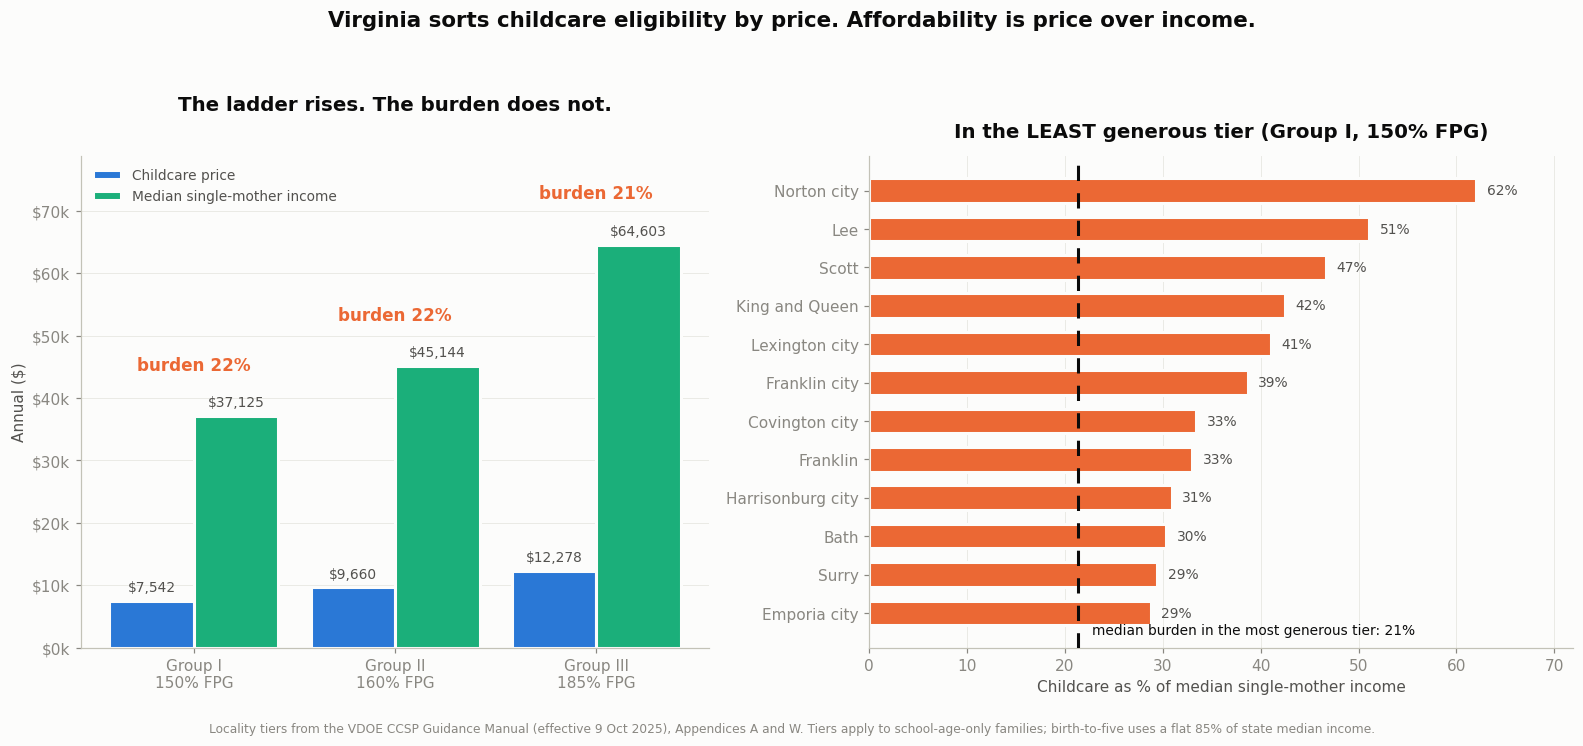

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.4),
                         gridspec_kw={"width_ratios": [1, 1.12]})
GROUPS = ["I (150% FPG)", "II (160% FPG)", "III (185% FPG)"]

x = np.arange(len(GROUPS))
price = [ladder.loc[g, "median_childcare_price"] for g in GROUPS]
income = [ladder.loc[g, "median_mother_income"] for g in GROUPS]
burden = [ladder.loc[g, "median_burden_pct"] for g in GROUPS]

axes[0].bar(x - 0.21, price, width=0.42, color=CAT[0], edgecolor=SURFACE, linewidth=2,
            label="Childcare price")
axes[0].bar(x + 0.21, income, width=0.42, color=CAT[2], edgecolor=SURFACE, linewidth=2,
            label="Median single-mother income")
for i, (p, inc, b) in enumerate(zip(price, income, burden)):
    axes[0].annotate(f"${p:,.0f}", (i - 0.21, p), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=9, color=INK_2)
    axes[0].annotate(f"${inc:,.0f}", (i + 0.21, inc), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=9, color=INK_2)
    axes[0].annotate(f"burden {b:.0f}%", (i, max(p, inc)), xytext=(0, 30),
                     textcoords="offset points", ha="center", fontsize=11,
                     fontweight="bold", color=CAT[1])
axes[0].set_xticks(x, ["Group I\n150% FPG", "Group II\n160% FPG", "Group III\n185% FPG"])
axes[0].set_ylabel("Annual ($)")
axes[0].set_title("The ladder rises. The burden does not.", pad=30)
axes[0].yaxis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}k")
axes[0].grid(axis="y", alpha=0.7); axes[0].set_axisbelow(True)
axes[0].margins(y=0.22)
axes[0].legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left")

top = misaligned.nlargest(12, "childcare_pct_of_mother_income").iloc[::-1]
y = np.arange(len(top))
axes[1].barh(y, top["childcare_pct_of_mother_income"], height=0.64, color=CAT[1],
             edgecolor=SURFACE, linewidth=2)
axes[1].axvline(group3_burden, color=INK, linewidth=2, linestyle=(0, (5, 4)), zorder=4)
axes[1].annotate(f"median burden in the most generous tier: {group3_burden:.0f}%",
                 xy=(group3_burden, 0.02), xycoords=("data", "axes fraction"),
                 xytext=(9, 0), textcoords="offset points", fontsize=9, color=INK, va="bottom")
for i, v in enumerate(top["childcare_pct_of_mother_income"]):
    axes[1].annotate(f"{v:.0f}%", (v, i), xytext=(7, 0), textcoords="offset points",
                     va="center", fontsize=9, color=INK_2)
axes[1].set_yticks(y, [n.replace(" County", "") for n in top["locality"]])
axes[1].set_xlabel("Childcare as % of median single-mother income")
axes[1].set_title("In the LEAST generous tier (Group I, 150% FPG)", pad=12)
axes[1].grid(axis="x", alpha=0.7); axes[1].set_axisbelow(True)
axes[1].margins(x=0.16)

fig.suptitle("Virginia sorts childcare eligibility by price. Affordability is price over income.",
             fontsize=14, fontweight="bold", color=INK, y=0.995)
fig.text(0.5, -0.03,
         "Locality tiers from the VDOE CCSP Guidance Manual (effective 9 Oct 2025), Appendices A and W. "
         "Tiers apply to school-age-only families; birth-to-five uses a flat 85% of state median income.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGDIR / "11_eligibility_ladder_misaligned.png", bbox_inches="tight")
plt.show()

## 17 · What is established so far, and what comes next

**Established.** A verified locality-level count of single-parent households for all 133 Virginia
localities, on **two definitions** rather than one — a wide count (no spouse: 266,921 statewide) and a
strict count (no spouse or partner: 200,974 statewide) — each with official 90% margins of error and a
reliability classification. Both reconcile exactly with the published state estimates, and the two
tables reconcile with each other to within 0.09%. On top of that, a complete-coverage poverty rate
for single-parent families in every locality, benchmarked against married-couple families on an
identical universe, plus median income reported separately for single-mother and single-father
families where published. Source and vintage are recorded, variable codes are
asserted against live metadata, and suppressed values are preserved as missing rather than imputed.

**Headline findings.** Statewide, 23.9% of single-parent families with children live below the
poverty line, against 4.1% of married-couple families with children — a 5.8x gap. Median family
income is $44,383 for single-mother families and $150,318 for married-couple families with children.
Among localities with reliable estimates, single-parent poverty runs from 4.3% (Greensville County)
to 47.5% (Tazewell County). On housing, 58.7% of these families rent, and in **66 of the 120
localities** where both figures are published, the median 2-bedroom rent exceeds 30% of the median
single-mother income — a median shortfall of **$288 a month**, with a statewide median rent burden of
**32.1%** of gross income. Bringing in the Datathon datasets, childcare for one toddler takes a
median **21.6%** of single-mother income and exceeds 30% in 18 localities; a partial budget of rent,
childcare and transport alone consumes a median **92%** of her income and **exceeds it outright in 44
of the 120 measurable localities**. Against the ALICE Household Survival Budget, Virginia's median
single-mother income falls **$6,797** short for one school-age child and **$16,421** short when that
child needs childcare.

**A result that inverts the usual assumption.** Transportation costs *more* in poor rural localities
than in dense affluent ones — $15,041 a year in Lee County against $12,881 in Falls Church city —
because car dependency does not fall with income. Rural localities are cheaper on rent and more
expensive on getting to work, which is why a housing-only affordability measure misreads them.

**The completed budget.** With food and health care added, the median single mother's income covers
the budget in almost no locality: the budget **exceeds her income in 101 of 120 measurable
localities** for a school-age child (median 132% of income, median shortfall **$14,332**) and in **103
of 120** for a preschool child. Worst: Lee County at **393%** of her income, Norton city 385%, Scott
County 357%. The 17 localities where it balances do so mainly because single-mother income there is
unusually high (Fluvanna $103,205; Falls Church city $100,605), not because costs are low.

**An independent method agrees.** ALICE publishes its own locality-varying survival threshold, built
from a different methodology. Median single-mother income falls below the local ALICE threshold in
**119 of 122** localities — against our own finding of 101-103 of 120. Two independent
constructions converging on the same conclusion is the strongest evidence in this notebook. Within the cohort, single mothers are **2.1x** as likely to be in
poverty as single fathers (27.8% vs 13.0%), and 34.7% of single-parent families have a child under 6.
By householder race and ethnicity, statewide rates run from 13.0% (Asian alone) to 28.1% (Black alone).

**Two segmentations are deliberately absent.** Race and ethnicity are reported statewide only, because
Virginia's small localities produce structural zeros that would make locality rates meaningless.
Never-married versus divorced/separated status is not reported at all, because no published ACS table
crosses householder marital status with single-parent family status — it exists only in PUMA-coded
PUMS microdata. Neither gap is approximated.

**Definition note for anyone comparing against other published figures.** Virginia dashboards often
cite a figure near 24% from table `B09005`, whose universe is **children**, not households: about 24%
of Virginia *children* live with a single parent. That is not the same statistic as the ~12% of
*families* reported here, and the two are not in conflict. Any headline must state its universe.

**Not yet established.** This is the *denominator* of the affordability question — who and where.
It says nothing yet about cost. The affordability gap requires, in order:

1. ~~**Income**~~ — done in §6 via `B17010` (poverty, complete coverage,
   all 133 localities) and `B19126` (medians, partial coverage, reported separately).
2. ~~**Housing cost**~~ — done in §8 via `B25031` (2-bedroom median rent),
   `B25115` (owner/renter split) and the 30%-of-income cost-burden test.
3. ~~**Childcare**~~ — done in §9 via the National Database of Childcare Prices
   (all 133 localities, by age of child and care setting), with transportation from the H+T Index.
4. ~~**A full household budget**~~ — done in §§9-10. Rent, childcare and transportation
   vary by locality; food and health care enter as statewide constants because neither varies by
   locality in its source methodology. Technology, miscellaneous and taxes remain excluded, so the
   budget is a conservative floor.

**The true-cost rate (§12).** Adopting the NYC True Cost of Living method turns the median test into
a population rate, on better coverage: **55.9%** of Virginia single-parent families fall below a
survival budget and **41.7%** below 75% of it, against an official poverty rate of **23.9%**. The
poverty measure therefore misses **32 percentage points** of this population. At Virginia's 2026
minimum wage of $12.77, full-time work covers **51%** of the median locality budget; meeting it would
take **79 hours a week** — close to NYC's 90. Because benefits are not netted in, this rate is
biased upward by roughly the 5-point margin NYC measures for non-market resources.

**Remaining limitations, stated plainly.** The §§9-10 budget carries no margins of error, because
neither the childcare nor the transportation source publishes them. It models one child, while 34.7%
of these families have a child under 6 and many have more than one. It uses the wide definition of
single parent, since no locality-level cost or income table separates cohabiting couples. And it mixes
vintages from 2022 to 2024. None of these is fatal to the conclusion, whose margin is very large, but
each should be stated before the conclusion is.

**One asymmetry worth presenting.** The largest dollar gaps and the heaviest burdens are in
different places. Alexandria city has the biggest monthly shortfall ($963) because rent is high;
Lee County has the heaviest burden (80% of a single mother's income) because income is low. A single
ranking hides this, so both are reported.

Every downstream step must be computed on **both** the wide and strict definitions, because the
cohabiting wedge is not uniform across the state: it is 8% of the wide count in Lynchburg city but 52%
in Buchanan County, so the choice of definition reorders localities rather than shifting them all
equally.

Each of those is added as its own verified step, on the same rule: no value enters this notebook
without a checked source.